In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import mdtraj as md
from scipy.spatial.distance import pdist, squareform
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# Extra packages for this notebook:  pip install igraph h5py huggingface_hub
import igraph as ig

In [3]:
# pip install igraph h5py huggingface_hub

## Settings

Same choices as in the first notebook: every 5th frame, contacts below 8 Å, and windows of 20 frames (1 ns) with 0.8 overlap.

In [4]:
PROTEINS = ["1a62_A", "16pk_A", "1k5n_A"]

STRIDE = 5                  # every 5th frame -> ~2000 frames over 100 ns
CONTACT_THRESHOLD = 8.0     # Å
WIDTH, OVERLAP = 20, 0.8    # sliding window: 20 frames (1 ns), 80% overlap
RANDOM_STATE = 42


def file_paths(protein):
    folder = f"{protein}_protein"
    return f"{folder}/{protein}.pdb", f"{folder}/{protein}_prod_R1_fit.xtc"

## Helper functions

The same helpers as in the first notebook, collected in one cell:

- `load_ca`: load a trajectory, keep the CA atoms, coordinates in Å.
- `contact_table`: one row per frame, one column per residue pair (True = contact).
- `window_mean`: average any per-frame array over sliding windows.
- `plot_projection`: scatter plot of a 2D projection, with lines between consecutive points.

In [5]:
def load_ca(protein, stride=STRIDE):
    pdb, xtc = file_paths(protein)
    traj = md.load(xtc, top=pdb, stride=stride)
    traj = traj.atom_slice(traj.topology.select("name CA"))
    return {"traj": traj, "coords": traj.xyz * 10, "time_ns": traj.time / 1000}


def contact_table(coords, threshold=CONTACT_THRESHOLD):
    """(frames, residue pairs) boolean table; column order = np.triu_indices(N, k=1)."""
    return np.array([pdist(frame) < threshold for frame in coords])


def step_for(width, overlap):
    return max(1, int(round(width * (1 - overlap))))


STEP = step_for(WIDTH, OVERLAP)


def window_mean(values, width=WIDTH, step=STEP):
    starts = np.arange(0, len(values) - width + 1, step)
    return np.array([values[s:s + width].mean(axis=0) for s in starts])


def plot_projection(ax, Y, colour, title, colour_label, connect=True, cmap="viridis"):
    if connect:
        ax.plot(Y[:, 0], Y[:, 1], lw=0.3, c="gray", alpha=0.6, zorder=1)
    sc = ax.scatter(Y[:, 0], Y[:, 1], c=colour, s=4, zorder=2, cmap=cmap)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(sc, ax=ax, label=colour_label)


def varying_columns(X):
    """Columns whose value changes at least once (constant columns carry no information)."""
    if X.dtype == bool:
        return X.any(axis=0) & ~X.all(axis=0)
    return X.std(axis=0) > 0


def changing_contacts(coords, threshold=CONTACT_THRESHOLD):
    """Contact table with only the contacts that change, as float (keeps memory low for big proteins)."""
    C = contact_table(coords, threshold)
    return C[:, varying_columns(C)].astype(np.float32)

In [6]:
data = {}
for p in PROTEINS:
    if not os.path.exists(file_paths(p)[1]):
        print(f"{p}: files not found, skipped")
        continue
    data[p] = load_ca(p)
    M, N, _ = data[p]["coords"].shape
    print(f"{p}: {M} frames, {N} residues")

1a62_A: 2001 frames, 130 residues
16pk_A: 2001 frames, 415 residues
1k5n_A: 2001 frames, 276 residues


## 1. Centrality vectors

### The idea

So far, each frame was described by **one value per residue pair** (contact or no contact): 8,385 columns for 1a62_A.
Here, each frame is described by **one value per residue**: how central that residue is in the frame's contact network.
That gives one column per residue (130 for 1a62_A), so frame *t* becomes the vector

  **v**(t) = (centrality of residue 0, centrality of residue 1, …, centrality of residue N−1).

Then the same steps as before: windows, PCA and t-SNE, time vs. PC1.

### Four centralities

| Centrality | What it measures for a residue | In protein terms |
| --- | --- | --- |
| **Degree** | Number of contacts | How buried/packed the residue is |
| **Closeness** | 1 / average shortest-path length to all other residues | How close it is to the "middle" of the network |
| **Betweenness** | How many shortest paths between other residues pass through it | Whether it is a bridge, e.g. a hinge between domains |
| **Eigenvector** | High if its neighbours are themselves central | Whether it sits in a densely connected core |

In [7]:
# handles one frame and gives 4 centrality measures for every residue
def frame_centralities(frame_coords, threshold=CONTACT_THRESHOLD):
    """Degree, closeness, betweenness and eigenvector centrality of every residue in one frame."""
    # contact map, adjacency matrix
    N = len(frame_coords)
    A = squareform(pdist(frame_coords) < threshold)          # N x N adjacency, no self-loops
    # turn grid into graph and compute centralities
    # keep only the upper half, list positions of all True cells
    i, j = np.nonzero(np.triu(A, k=1))
    # build a network
    g = ig.Graph(n=N, edges=list(zip(i.tolist(), j.tolist())))
    return {
        "degree": A.sum(axis=1).astype(float),
        "closeness": np.nan_to_num(np.array(g.closeness(), dtype=float)),
        "betweenness": np.array(g.betweenness(), dtype=float),
        "eigenvector": np.array(g.eigenvector_centrality(), dtype=float),
    }

CENTRALITIES = ["degree", "closeness", "betweenness", "eigenvector"]

# all frames -> one table per centrality
def centrality_vectors(coords, threshold=CONTACT_THRESHOLD):
    """dict: centrality name -> (frames, residues) array."""
    per_frame = [frame_centralities(f, threshold) for f in coords]
    return {c: np.array([fc[c] for fc in per_frame]) for c in CENTRALITIES}


cent = {}
for p in data:
    cent[p] = centrality_vectors(data[p]["coords"])
    print(f"{p}: centrality vectors, shape {cent[p]['degree'].shape} (frames, residues)")

1a62_A: centrality vectors, shape (2001, 130) (frames, residues)
16pk_A: centrality vectors, shape (2001, 415) (frames, residues)
1k5n_A: centrality vectors, shape (2001, 276) (frames, residues)


In [8]:
cent[p]

{'degree': array([[ 5.,  7., 10., ..., 10.,  4.,  2.],
        [ 5.,  8., 10., ...,  9.,  3.,  2.],
        [ 5.,  8.,  9., ...,  9.,  3.,  2.],
        ...,
        [12., 10., 12., ...,  9.,  5.,  2.],
        [12., 12., 10., ..., 11.,  5.,  4.],
        [11., 12., 10., ...,  9.,  4.,  3.]], shape=(2001, 276)),
 'closeness': array([[0.19230769, 0.19448373, 0.21585557, ..., 0.13980681, 0.13722555,
         0.12276786],
        [0.18978606, 0.19393512, 0.21417445, ..., 0.13917004, 0.1280857 ,
         0.12227657],
        [0.1880985 , 0.18835616, 0.21137586, ..., 0.13987792, 0.1241535 ,
         0.12282269],
        ...,
        [0.21186441, 0.20568437, 0.21894904, ..., 0.13647643, 0.12178919,
         0.12019231],
        [0.21024465, 0.21982414, 0.21653543, ..., 0.1400917 , 0.1245471 ,
         0.1238181 ],
        [0.20976354, 0.21894904, 0.21808089, ..., 0.13784461, 0.12195122,
         0.12152011]], shape=(2001, 276)),
 'betweenness': array([[2.09896108e+02, 2.90051078e+01, 7.46452

### Projections: edge vector vs. centrality vectors

Rows: the edge vector from the first notebook (baseline), then the four centralities.
Columns: PCA, t-SNE, and time vs. PC1. All use the same windows (1 ns, 0.8 overlap).

**Scaling.** Within one centrality, all columns have the same unit, so no normalization is needed (as for the edge vector).
Set `SCALE = True` to z-score each residue's column instead; residues whose centrality barely changes then get as much weight as the others.

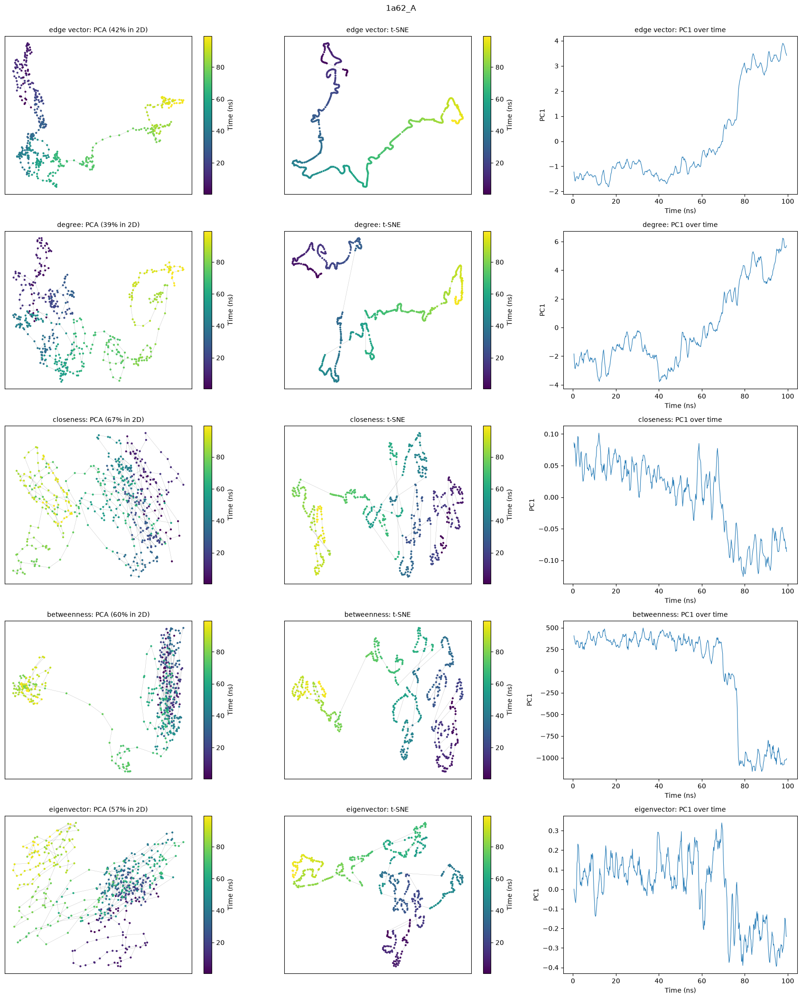

In [9]:
PROTEIN = "1a62_A"
SCALE = False

# collects five tables for one protein: edge vector + the four centralities
# each goes through a sliding window (20 frames, 80% overlap)
def representations(p):
    """Windowed feature tables for one protein: edge vector + the four centralities."""
    reps = {"edge vector": window_mean(changing_contacts(data[p]["coords"]))}
    for c in CENTRALITIES:
        reps[c] = window_mean(cent[p][c])
    return reps

# drop cols that never change
# optional scaling (StandardScaler) to mean=0, std=1. false for now
# PCA and t-SNE to 2D
def project(X, scale=SCALE, tsne=True):
    X = X[:, varying_columns(X)]
    if scale:
        X = StandardScaler().fit_transform(X)
    pca = PCA(n_components=2).fit(X)
    out = {"pca": pca.transform(X), "var": pca.explained_variance_ratio_, "components": pca.components_}
    if tsne:
        out["tsne"] = TSNE(n_components=2, perplexity=30, init="pca",
                           random_state=RANDOM_STATE).fit_transform(X)
    return out

reps = representations(PROTEIN)
tW = window_mean(data[PROTEIN]["time_ns"])
proj = {name: project(X) for name, X in reps.items()}

fig, axes = plt.subplots(len(reps), 3, figsize=(17, 4.2 * len(reps)))
for row, (name, P) in zip(axes, proj.items()):
    plot_projection(row[0], P["pca"], tW, f"{name}: PCA ({P['var'].sum():.0%} in 2D)", "Time (ns)")
    plot_projection(row[1], P["tsne"], tW, f"{name}: t-SNE", "Time (ns)")
    row[2].plot(tW, P["pca"][:, 0], lw=0.8)
    row[2].set_title(f"{name}: PC1 over time", fontsize=10)
    row[2].set_xlabel("Time (ns)"); row[2].set_ylabel("PC1")
fig.suptitle(PROTEIN, y=1.0)
plt.tight_layout()
plt.show()

betweeenness: 
During 0–70 ns, betweenness doesn’t drift. The colours mix in one cluster, while the edge vector shows a slow drift through that period. So the gradual changes in contacts during the first 70 ns don’t change which residues act as bridges; they’re local changes. Betweenness only reacts when the network’s path structure changes.
The switch has two steps: a first one at about 70 ns and the main one at about 77 ns. The heatmap below shows what happens in between.

The centralities explain more variance in 2D (closeness 67%, betweenness 60%, eigenvector 57%) than the edge vector (42%) or degree (39%). That’s mostly because they have far fewer columns (130, not 439), many of which move together. It isn’t a quality score in itself; betweenness happens to also look the cleanest, but closeness explains the most variance and looks the noisiest.

In [10]:
rows = []
for p in data:
    reps = {"edge vector": contact_table(data[p]["coords"])}          # all residue pairs, per frame
    reps.update({c: cent[p][c] for c in CENTRALITIES})                  # all residues, per frame
    for name, X in reps.items():
        n_total = X.shape[1]
        n_const_frames = (~varying_columns(X)).sum()                    # constant over all frames
        W = window_mean(X.astype(np.float32))
        n_const_windows = (~varying_columns(W)).sum()                   # constant over all windows
        rows.append({"protein": p, "representation": name, "columns": n_total,
                     "constant (frames)": n_const_frames, "constant (windows)": n_const_windows,
                     "% removed": round(100 * n_const_windows / n_total, 1)})

import pandas as pd
pd.DataFrame(rows)

,protein,representation,columns,constant (frames),constant (windows),% removed
0,1a62_A,edge vector,8385,7946,7946,94.8
1,1a62_A,degree,130,0,0,0.0
2,1a62_A,closeness,130,0,0,0.0
3,1a62_A,betweenness,130,0,0,0.0
4,1a62_A,eigenvector,130,0,0,0.0
5,16pk_A,edge vector,85905,84574,84574,98.5
6,16pk_A,degree,415,4,4,1.0
7,16pk_A,closeness,415,0,0,0.0
8,16pk_A,betweenness,415,0,0,0.0
9,16pk_A,eigenvector,415,0,0,0.0


- Edge vector: 95–98.5% of columns are constant and get dropped. For the bigger proteins, even more are constant (98.5% for 16pk_A), because most residue pairs are far apart and never touch.
- Closeness, betweenness and eigenvector: nothing removed for any protein. Every residue’s value changes at least a little.
- Degree: only 4 residues in 16pk_A and 1 in 1k5n_A are constant. Their contact count never changes in any frame, probably residues in a very stable part of the structure.

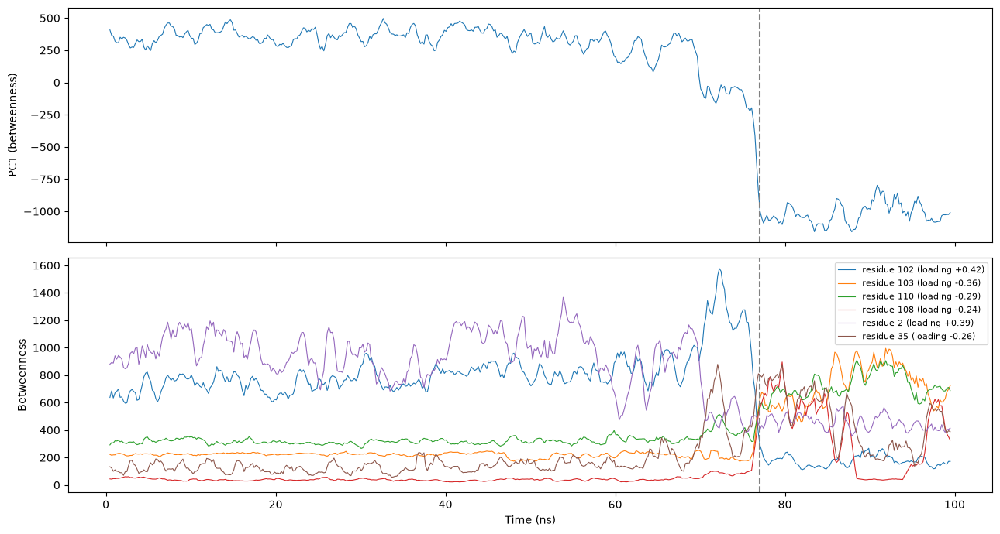

PC1 falls at the switch

residue 102: before     816, after     176, change    -640, loading +0.42 -> consistent
residue 103: before     221, after     739, change    +519, loading -0.36 -> consistent
residue 110: before     325, after     735, change    +411, loading -0.29 -> consistent
residue 108: before      42, after     331, change    +289, loading -0.24 -> consistent
residue   2: before     942, after     453, change    -489, loading +0.39 -> consistent
residue  35: before     164, after     440, change    +276, loading -0.26 -> consistent


In [11]:
p = "1a62_A"
RESIDUES = [102, 103, 110, 108, 2, 35]   # top residues from the loadings printout
SWITCH = 77                              # ns

t = window_mean(data[p]["time_ns"])
B = window_mean(cent[p]["betweenness"])          # windows x residues
pca = PCA(n_components=1).fit(B)
pc1 = pca.transform(B)[:, 0]
loadings = pca.components_[0]

# 1. PC1 and the residues' betweenness over time
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(t, pc1, lw=0.8)
axes[0].set_ylabel("PC1 (betweenness)")
for r in RESIDUES:
    axes[1].plot(t, B[:, r], lw=0.8, label=f"residue {r} (loading {loadings[r]:+.2f})")
axes[1].set_ylabel("Betweenness"); axes[1].set_xlabel("Time (ns)"); axes[1].legend(fontsize=8)
for ax in axes:
    ax.axvline(SWITCH, ls="--", c="gray")
plt.tight_layout(); plt.show()

# 2. Before vs. after the switch
before = B[t < SWITCH - 2].mean(axis=0)
after = B[t > SWITCH + 2].mean(axis=0)
pc1_falls = pc1[t > SWITCH + 2].mean() < pc1[t < SWITCH - 2].mean()
print(f"PC1 {'falls' if pc1_falls else 'rises'} at the switch\n")
for r in RESIDUES:
    change = after[r] - before[r]
    expected = -np.sign(loadings[r]) if pc1_falls else np.sign(loadings[r])   # direction the loading predicts
    ok = "consistent" if np.sign(change) == expected else "NOT consistent"
    print(f"residue {r:>3}: before {before[r]:7.0f}, after {after[r]:7.0f}, change {change:+7.0f}, "
          f"loading {loadings[r]:+.2f} -> {ok}")

### Time vs. PC1 for every protein and representation

PC1 is scaled to mean 0 and standard deviation 1 per line, so the shapes can be compared (the sign of PC1 is arbitrary, so a line may be upside down).
Matching jumps across representations mean they detect the same transition.

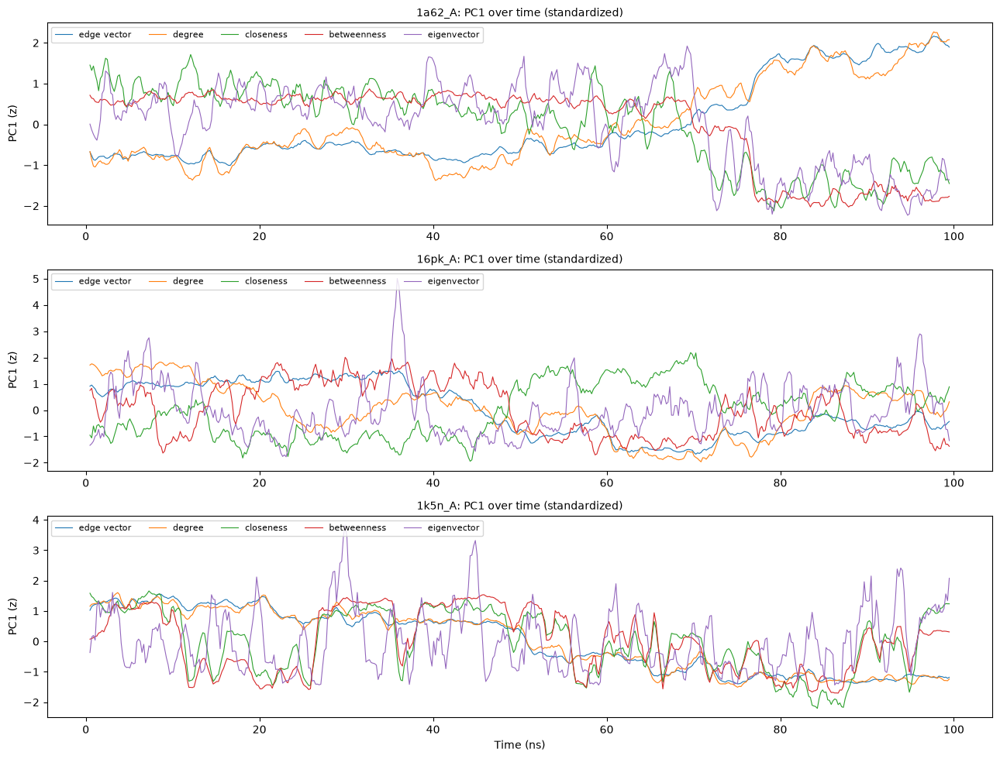

In [12]:
fig, axes = plt.subplots(len(data), 1, figsize=(13, 3.3 * len(data)), squeeze=False)
for ax, p in zip(axes[:, 0], data):
    t = window_mean(data[p]["time_ns"])
    for name, X in representations(p).items():
        pc1 = project(X, tsne=False)["pca"][:, 0]
        ax.plot(t, (pc1 - pc1.mean()) / pc1.std(), lw=0.8, label=name)
    ax.set_title(f"{p}: PC1 over time (standardized)", fontsize=10)
    ax.set_ylabel("PC1 (z)")
    ax.legend(fontsize=8, ncol=5, loc="upper left")
axes[-1, 0].set_xlabel("Time (ns)")
plt.tight_layout()
plt.show()

### Which residues change? Centrality over time

The advantage of one value per residue: you can draw the whole feature table as an image.
Each row is a residue, each column a window in time, colour = centrality. Horizontal bands that change colour at some time point are residues whose role changes.

Below each heatmap, the **PC1 loadings**: how strongly each residue's centrality drives PC1. Tall bars (positive or negative) mark the residues that separate the states along PC1.

degree: residues with the largest PC1 loadings: 89 (+0.32), 109 (-0.30), 111 (-0.27), 126 (-0.27), 102 (-0.26), 2 (-0.24), 122 (-0.23), 39 (+0.21), 38 (-0.20), 88 (+0.18)
betweenness: residues with the largest PC1 loadings: 102 (+0.42), 2 (+0.39), 103 (-0.36), 110 (-0.29), 35 (-0.26), 108 (-0.24), 31 (+0.23), 76 (+0.20), 111 (+0.19), 3 (-0.17)


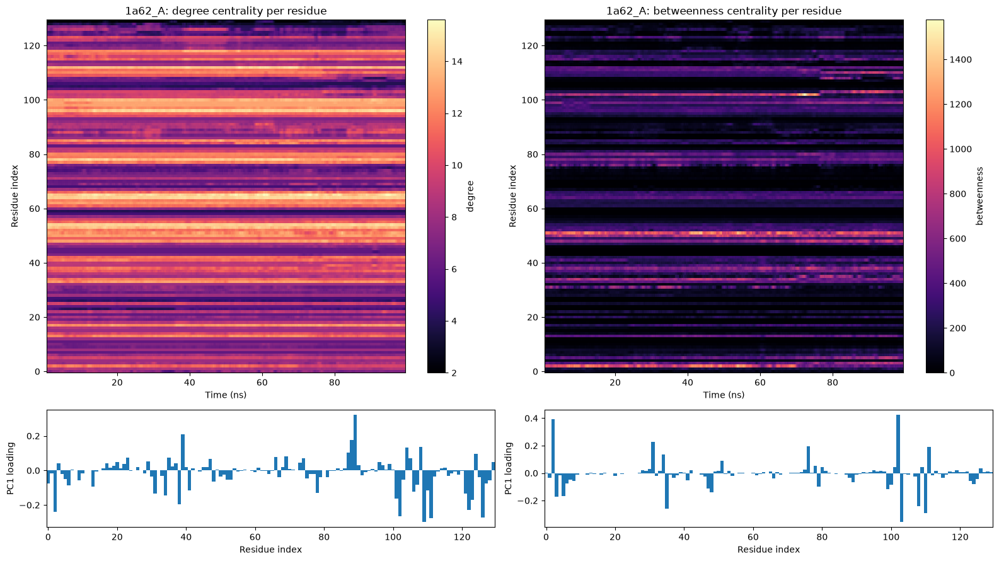

In [13]:
SHOW = ["degree", "betweenness"]
TOP = 10

p = PROTEIN
t = window_mean(data[p]["time_ns"])
fig, axes = plt.subplots(2, len(SHOW), figsize=(8 * len(SHOW), 9),
                         gridspec_kw={"height_ratios": [3, 1]}, squeeze=False)
for col, c in enumerate(SHOW):
    X = window_mean(cent[p][c])
    N = X.shape[1]
    # each pixel's color is that residue's centrality at that time window
    im = axes[0, col].imshow(X.T, aspect="auto", origin="lower", cmap="magma",
                             extent=[t[0], t[-1], -0.5, N - 0.5], interpolation="nearest")
    axes[0, col].set_title(f"{p}: {c} centrality per residue")
    axes[0, col].set_xlabel("Time (ns)"); axes[0, col].set_ylabel("Residue index")
    plt.colorbar(im, ax=axes[0, col], label=c)

    loadings = np.zeros(N)
    keep = varying_columns(X)
    # PCA on the residues that change, then put the loadings back into a full-length array
    loadings[keep] = PCA(n_components=1).fit(X[:, keep]).components_[0]
    axes[1, col].bar(np.arange(N), loadings, width=1.0)
    axes[1, col].set_xlim(-0.5, N - 0.5)
    axes[1, col].set_xlabel("Residue index"); axes[1, col].set_ylabel("PC1 loading")
    top = np.argsort(-np.abs(loadings))[:TOP]
    print(f"{c}: residues with the largest PC1 loadings:",
          ", ".join(f"{r} ({loadings[r]:+.2f})" for r in top))
plt.tight_layout()
plt.show()

1. Degree carries about the same information as the edge vector, summed per residue: it shows gradual change plus the switch, and its loadings point to the same residues as your contact analysis.
2. Betweenness gives the cleanest picture of 1a62_A: one stable state from 0 to ~70 ns, a two-step transition (~70 and ~77 ns) and a second stable state. The heatmap and loadings show which residues change role: 102 is the bridge during the transition, and 103 and 108–110 take over afterwards.
3. Closeness and eigenvector detect the switch but are too noisy, especially eigenvector, which spikes in all three proteins.
4. For 1k5n_A, betweenness and closeness catch the between-part events (α3 at 15–30 ns, the new interface at the end) that the edge vector underplays. For 16pk_A, no representation shows one clear event, consistent with its two domains changing at different times.
5. New leads to check: residues 88–89 (gaining contacts) and 76 (losing its bridge role) in 1a62_A, which didn’t show up in the earlier analysis. The nglview cell from part 1, with these residues highlighted, would show what they do.

## 2. A bigger and more varied dataset: mdCATH

### Why mdCATH

ATLAS simulations are short (100 ns) and run at room temperature, starting from the folded structure, so the proteins mostly fluctuate around one shape.
**mdCATH** ([Mirarchi et al. 2024](https://arxiv.org/abs/2407.14794)) has:

- 5,398 protein domains (50–500 residues),
- each simulated at **five temperatures: 320, 348, 379, 413 and 450 K**, with five replicas per temperature,
- mostly **500 ns** per trajectory, one frame per ns.

At 413 K and especially 450 K many domains partly or fully unfold, so one domain gives you trajectories ranging from "stable" to "unfolding". That is the variation ATLAS lacks.

### How the data is stored

One HDF5 file per domain, downloaded from Hugging Face (about 0.6 GB per domain on average, covering all 25 trajectories). Inside:
`<domain>/pdbProteinAtoms` (the structure), and `<domain>/<temperature>/<replica>/coords` with shape (frames, atoms, 3) in Å.

### What the cells below do

1. Download one domain (or reuse a downloaded file).
2. Load one replica at several temperatures and keep the CA atoms.
3. Put **all temperatures into one shared projection**, so you can see whether high-temperature runs move away from the folded region, and whether different temperatures visit the same states.

The default domain, `5sicI00`, is the example in the mdCATH paper that stays folded at lower temperatures and unfolds at 450 K. Any other domain ID from the dataset works the same way.

An mdCATH file is an HDF5 file: a container organised like folders inside one file:

5sicI00/
├── pdbProteinAtoms      ← the structure, as PDB text
├── 320/                 ← temperature
│   ├── 0/coords         ← replica 0: (frames × atoms × 3), in Å
│   ├── 1/coords
│   └── …
├── 348/ …
└── 450/ …

In [14]:
import h5py
from huggingface_hub import hf_hub_download

MDCATH_DOMAIN = "5sicI00"
TEMPERATURES = [320, 379, 413, 450]   # choose from 320, 348, 379, 413, 450
REPLICA = 0                           # 0-4
MDCATH_DIR = "mdcath"

# find or downdload
def mdcath_file(domain):
    local = os.path.join(MDCATH_DIR, "data", f"mdcath_dataset_{domain}.h5")
    if os.path.exists(local):
        return local
    return hf_hub_download(repo_id="compsciencelab/mdCATH", filename=f"mdcath_dataset_{domain}.h5",
                           subfolder="data", local_dir=MDCATH_DIR, repo_type="dataset")

# read the file
def load_mdcath(domain, temperatures, replica=0):
    """CA coordinates (Å) per temperature: dict T -> {"coords", "time_ns"}; plus the CA topology."""
    path = mdcath_file(domain)
    with h5py.File(path, "r") as f:
        g = f[domain]
        pdb_text = g["pdbProteinAtoms"][()]
        pdb_text = pdb_text.decode() if isinstance(pdb_text, bytes) else str(pdb_text)
        tmp = os.path.join(MDCATH_DIR, f"{domain}_protein.pdb")
        with open(tmp, "w") as out:
            out.write(pdb_text)
        top = md.load_pdb(tmp).topology
        # find CA atoms
        ca = top.select("name CA")
        runs = {}
        # for each temp, reads coords and keep only teh CA atoms
        for T in temperatures:
            coords = g[str(T)][str(replica)]["coords"][:]          # (frames, atoms, 3), Å
            if coords.shape[1] != top.n_atoms:
                raise ValueError(f"{T} K: {coords.shape[1]} atoms in coords, {top.n_atoms} in the structure")
            runs[T] = {"coords": coords[:, ca], "time_ns": np.arange(len(coords), dtype=float)}  # 1 frame per ns
    return runs, top.subset(ca)


runs, mdcath_top = load_mdcath(MDCATH_DOMAIN, TEMPERATURES, REPLICA)
for T, r in runs.items():
    print(f"{MDCATH_DOMAIN} {T} K: {r['coords'].shape[0]} frames, {r['coords'].shape[1]} residues")

5sicI00 320 K: 500 frames, 107 residues
5sicI00 379 K: 130 frames, 107 residues
5sicI00 413 K: 500 frames, 107 residues
5sicI00 450 K: 500 frames, 107 residues


### Sanity check: RMSD and radius of gyration per temperature

Before projecting, check that the temperatures really differ. RMSD to the first frame shows how far the structure moves; the radius of gyration shows how compact it is (it grows when the protein unfolds).

- RMSD to frame 0: how far the structure has moved from its start. It isn’t aligned here: mdCATH files aren’t pre-fitted, so overall rotation adds to it. That’s fine for a rough check.
- Radius of gyration: the average distance of the residues from the protein’s centre, i.e. how spread out it is. A folded protein is compact. If it unfolds, this number grows.

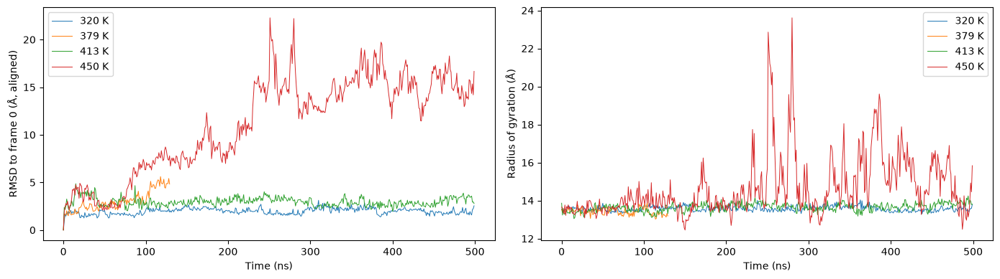

In [15]:
# check that the temperatures actually behave differently
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for T, r in runs.items():
    traj = md.Trajectory(r["coords"] / 10, mdcath_top)
    rmsd = md.rmsd(traj, traj, 0) * 10        # aligned RMSD in Å
    c = r["coords"]
    rg = np.sqrt(((c - c.mean(axis=1, keepdims=True)) ** 2).sum(-1).mean(-1))
    axes[0].plot(r["time_ns"], rmsd, lw=0.7, label=f"{T} K")
    axes[1].plot(r["time_ns"], rg, lw=0.7, label=f"{T} K")
axes[0].set_ylabel("RMSD to frame 0 (Å, aligned)"); axes[1].set_ylabel("Radius of gyration (Å)")
for ax in axes:
    ax.set_xlabel("Time (ns)"); ax.legend()
plt.tight_layout()
plt.show()

320 K (blue) stays around 1.5–2.5 Å for all 500 ns: the protein keeps its folded shape, with normal thermal wiggling.

413 K (green) sits slightly higher, around 2.5–4 Å, with a small bump early on (about 20–40 ns). Still folded, just moving more because of the heat. That matches the contact projection, where 413 K stayed near the folded region with brief dips.

379 K (orange) is short (130 ns, as noted before). It stays around 2–3 Å, then creeps up to about 5 Å in its last 30 ns. That’s unusual for a temperature below 413 K, but with such a short run it’s hard to say whether it’s a real change or a temporary excursion. Another replica would tell.

450 K (red) unfolds, and in steps:

about 4–5 Å in the first ~40 ns (similar to 413 K’s early bump),
rising from about 75–90 ns to 7–8 Å,
about 10–12 Å around 200–230 ns,
a jump to about 15 Å around 235 ns,
then 12–18 Å for the rest, with two spikes to about 22 Å at ~250 and ~280 ns.

Combined with the radius of gyration, this confirms the earlier conclusion, now with a reliable RMSD:

The two RMSD spikes at ~250 and ~280 ns line up with the two big radius-of-gyration spikes (about 23 Å): moments when the protein briefly swells.
Outside those spikes, after ~240 ns the RMSD stays at 12–18 Å while the radius of gyration is often back at about 13–14 Å, the same as the folded protein.

So the protein is compact but has a very different shape from its folded state: a compact, non-native state. By size alone it looks folded; by RMSD and native contacts, it clearly isn’t.

### One shared projection for all temperatures

All temperatures are stacked into one table and projected together, so positions are comparable across runs.
Left: coloured by temperature. Middle: coloured by time within each run. Right: PC1 over time per temperature.

Note that mdCATH coordinates are **not pre-aligned** like the ATLAS `_fit` files; contact-based features don't need alignment, which is one more reason to use them here.
With 1 frame per ns, a window of 5 frames covers 5 ns.

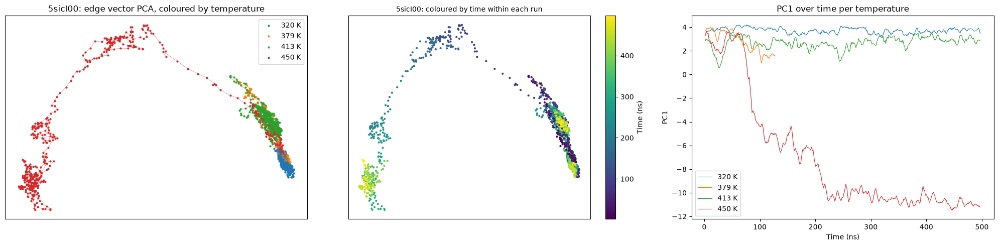

In [16]:
MDCATH_WIDTH, MDCATH_OVERLAP = 5, 0.8
mstep = step_for(MDCATH_WIDTH, MDCATH_OVERLAP)
REPRESENTATION = "edge vector"   # or one of CENTRALITIES, e.g. "betweenness"


def features(coords, representation):
    # Full contact table here: constant columns are dropped only after stacking all temperatures,
    # so every temperature keeps the same columns.
    if representation == "edge vector":
        return contact_table(coords)
    return centrality_vectors(coords)[representation]

# for each temperature, compute the features and average over windows of 5 frames
# and record the temperature and time for each window
blocks, temps, times = [], [], []
for T, r in runs.items():
    W = window_mean(features(r["coords"], REPRESENTATION), MDCATH_WIDTH, mstep)
    blocks.append(W)
    temps.append(np.full(len(W), T))
    times.append(window_mean(r["time_ns"], MDCATH_WIDTH, mstep))
# stack all temperatures, drop constant columns, and do PCA to 2D
X_all = np.vstack(blocks)
temps, times = np.concatenate(temps), np.concatenate(times)
X_all = X_all[:, varying_columns(X_all)]
Y = PCA(n_components=2).fit_transform(X_all)

# color by temperature, time, and PC1 over time per temperature
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for T in runs:
    sel = temps == T
    axes[0].plot(Y[sel, 0], Y[sel, 1], lw=0.4, alpha=0.7)
    axes[0].scatter(Y[sel, 0], Y[sel, 1], s=4, label=f"{T} K")
axes[0].legend(); axes[0].set_xticks([]); axes[0].set_yticks([])
axes[0].set_title(f"{MDCATH_DOMAIN}: {REPRESENTATION} PCA, coloured by temperature")
plot_projection(axes[1], Y, times, f"{MDCATH_DOMAIN}: coloured by time within each run", "Time (ns)", connect=False)
for T in runs:
    sel = temps == T
    axes[2].plot(times[sel], Y[sel, 0], lw=0.8, label=f"{T} K")
axes[2].set_xlabel("Time (ns)"); axes[2].set_ylabel("PC1"); axes[2].legend()
axes[2].set_title("PC1 over time per temperature")
plt.tight_layout()
plt.show()

## 3. Proteins with several domains: whole vs. parts

### The idea

A **domain** is a part of a protein that folds into its own compact unit. 1k5n_A is the heavy chain of the human immune protein HLA-B\*27:09 (an MHC class I molecule, 276 residues). It has two parts: a **peptide-binding platform** (the α1 and α2 regions, roughly the first 180 residues, which together hold a short peptide in a groove) and an **α3 domain** (roughly the last 95 residues, an immunoglobulin-like domain). The platform itself has two halves (α1 and α2), so it can also be split into three parts. 16pk_A has two domains (visible as two blocks in its contact map).

Note: the ATLAS entry contains only chain A. In the crystal structure, the heavy chain is bound to a second protein (β2-microglobulin) and a peptide, which are missing here, so the α3 domain and the groove may move more than they would in the full complex.

In a multi-domain protein, two kinds of motion mix:
- **inside a domain**: local changes, like the 1a62_A transition,
- **between domains**: the domains moving relative to each other, e.g. a hinge opening and closing.

Projecting the whole protein mixes both. Projecting each part separately shows which part is responsible for a pattern.

### The parts

Every residue pair (column of the contact table) belongs to exactly one part:
- **intra-domain contacts of domain k**: both residues in domain k,
- **inter-domain contacts**: the residues are in different domains.

Each part is projected on its own, with the same windows and PCA as before.

### Domain boundaries

Two options:
- **Manual:** type the boundaries in `MANUAL_DOMAINS` (0-based positions in the CA list), e.g. from CATH. Check how ATLAS numbers the residues first: the ATLAS chain can be shorter than the PDB chain.
- **Automatic (default):** spectral clustering on the average contact map splits the residues into `n_domains` groups that have many contacts inside and few between. Isolated residues are smoothed out. Always compare the result with the contact map and, if possible, with CATH.

In [17]:
from sklearn.cluster import SpectralClustering
from scipy.ndimage import median_filter

# how many parts; optionally the exact boundaries. with none, it finds them automatically
DOMAIN_SETUPS = {
    "1k5n_A": {"n_domains": 2, "manual": None},   # try 3 as well: alpha1 / alpha2 / alpha3
    "16pk_A": {"n_domains": 2, "manual": None},
}
# Manual example (0-based CA positions, end exclusive; a domain can have several segments):
# Approximate MHC class I boundaries, assuming the ATLAS chain starts at residue 1 (check the PDB file first):
# DOMAIN_SETUPS["1k5n_A"]["manual"] = {"platform (alpha1+alpha2)": [(0, 180)], "alpha3": [(180, 276)]}
# DOMAIN_SETUPS["1k5n_A"]["manual"] = {"alpha1": [(0, 90)], "alpha2": [(90, 180)], "alpha3": [(180, 276)]}


def contact_frequency(coords, threshold=CONTACT_THRESHOLD):
    return squareform(contact_table(coords, threshold).mean(axis=0))

# which residue belong to which part
def assign_domains(coords, n_domains, manual=None, smooth=9):
    """Domain label (0..n-1) per residue and the domain names."""
    N = coords.shape[1]
    if manual:
        labels = np.full(N, -1)
        for k, segments in enumerate(manual.values()):
            for start, end in segments:
                labels[start:end] = k
        if (labels < 0).any():
            print(f"warning: {(labels < 0).sum()} residues not in any domain; assigned to the nearest one")
            for r in np.flatnonzero(labels < 0):
                labels[r] = labels[np.flatnonzero(labels >= 0)[np.argmin(np.abs(np.flatnonzero(labels >= 0) - r))]]
        return labels, list(manual)
    freq = contact_frequency(coords)
    #automatically assign domains using spectral clustering on the contact frequency matrix
    labels = SpectralClustering(n_clusters=n_domains, affinity="precomputed",
                                random_state=RANDOM_STATE).fit_predict(freq + 1e-6)
    labels = median_filter(labels, size=smooth, mode="nearest")        # remove isolated residues
    order = {old: new for new, old in enumerate(dict.fromkeys(labels))}  # number domains along the chain
    labels = np.array([order[l] for l in labels])
    return labels, [f"domain {k}" for k in range(labels.max() + 1)]

# turns labels into text
def segments(labels, k):
    idx = np.flatnonzero(labels == k)
    breaks = np.flatnonzero(np.diff(idx) > 1)
    starts, ends = np.r_[idx[0], idx[breaks + 1]], np.r_[idx[breaks], idx[-1]]
    return ", ".join(f"{s}-{e}" for s, e in zip(starts, ends))


domains = {}
for p, setup in DOMAIN_SETUPS.items():
    if p not in data:
        continue
    labels, names = assign_domains(data[p]["coords"], setup["n_domains"], setup["manual"])
    domains[p] = {"labels": labels, "names": names}
    print(p)
    for k, name in enumerate(names):
        print(f"  {name}: residues {segments(labels, k)} ({(labels == k).sum()} residues)")

1k5n_A
  domain 0: residues 0-179 (180 residues)
  domain 1: residues 180-275 (96 residues)
16pk_A
  domain 0: residues 0-192, 404-414 (204 residues)
  domain 1: residues 193-403 (211 residues)


### Check the domains on the contact map

The average contact map with the domain of each residue as a coloured strip along both axes, and dashed lines at the boundaries.
Good domains look like dense square blocks on the diagonal with few contacts between them.

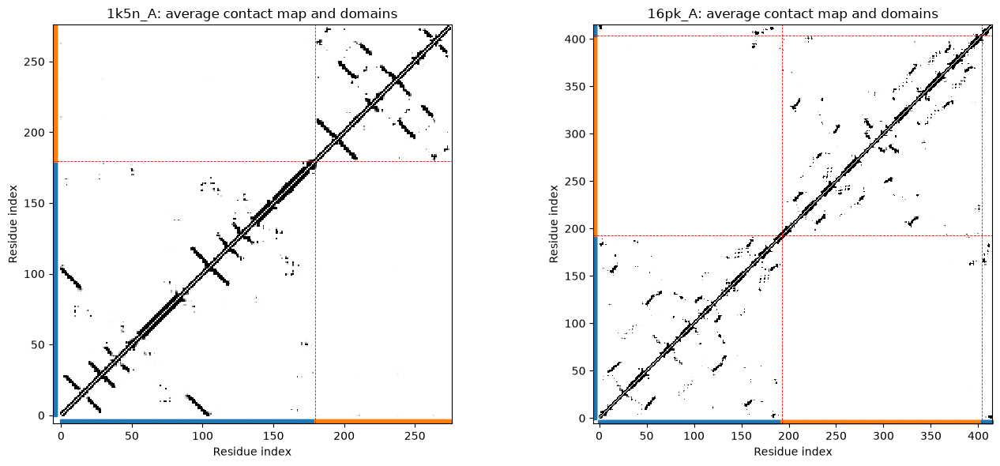

In [18]:
fig, axes = plt.subplots(1, len(domains), figsize=(7 * len(domains), 6), squeeze=False)
for ax, (p, d) in zip(axes[0], domains.items()):
    labels = d["labels"]
    N = len(labels)
    ax.imshow(contact_frequency(data[p]["coords"]), origin="lower", cmap="Greys", vmin=0, vmax=1,
              interpolation="nearest")
    colours = plt.cm.tab10(labels)
    ax.scatter(np.arange(N), np.full(N, -4), c=colours, s=6, marker="s", clip_on=False)
    ax.scatter(np.full(N, -4), np.arange(N), c=colours, s=6, marker="s", clip_on=False)
    for b in np.flatnonzero(np.diff(labels)) + 0.5:
        ax.axvline(b, ls="--", lw=0.6, c="red"); ax.axhline(b, ls="--", lw=0.6, c="red")
    ax.set_xlim(-6, N); ax.set_ylim(-6, N)
    ax.set_title(f"{p}: average contact map and domains")
    ax.set_xlabel("Residue index"); ax.set_ylabel("Residue index")
plt.tight_layout()
plt.show()

### Projections: whole protein vs. each domain vs. between domains

One column per part. Top: PCA projection coloured by time. Bottom: PC1 over time.
The title shows how many contacts change in that part.

**How to read it**

- A transition visible in the whole protein **and** in one domain's own contacts happens inside that domain.
- A transition visible in the whole protein **and** in the inter-domain contacts, but not inside the domains, is a motion of the domains relative to each other (e.g. a hinge).
- A pattern that only shows up in one part (not in the whole) was drowned out by the rest of the protein: projecting parts separately reveals it.

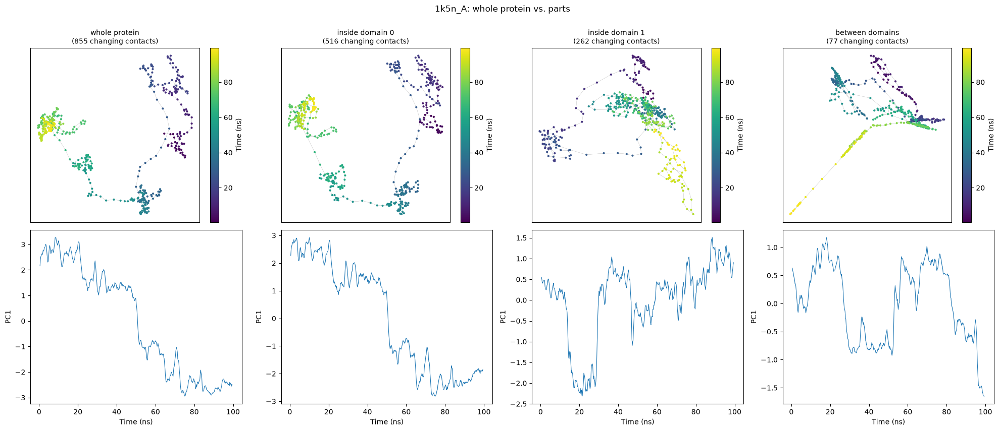

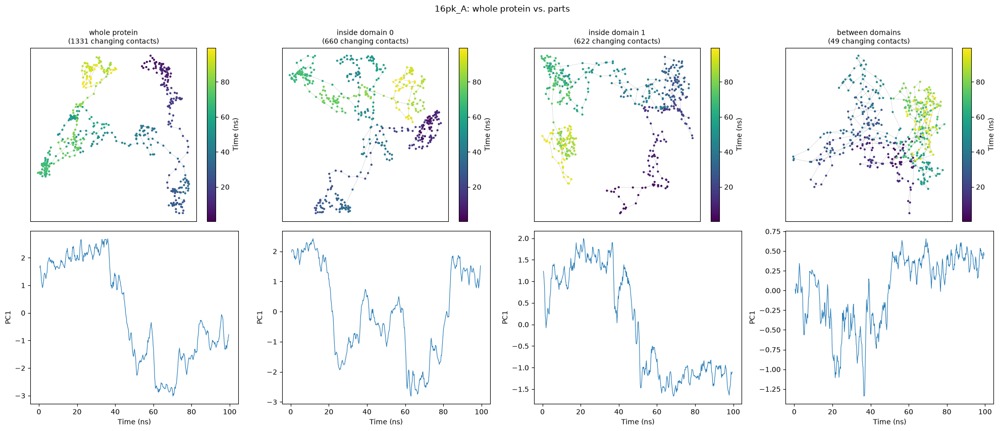

In [19]:
# sorting contacts into parts
def part_masks(labels, names):
    N = len(labels)
    # I, J are two residues of every column in the contact table
    I, J = np.triu_indices(N, k=1)
    # domain numbers
    li, lj = labels[I], labels[J]
    masks = {"whole protein": np.ones(len(I), bool)}
    # a contact is inside domain k if both residues belong to that domain
    for k, name in enumerate(names):
        masks[f"inside {name}"] = (li == k) & (lj == k)
    masks["between domains"] = li != lj
    return masks

# one projection per part
def part_projections(p, labels, names):
    C = contact_table(data[p]["coords"])
    changing = varying_columns(C)
    t = window_mean(data[p]["time_ns"])
    results = {}
    for part, mask in part_masks(labels, names).items():
        # only take the changing contacts for PCA, and average over windows
        X = window_mean(C[:, mask & changing].astype(np.float32))
        keep = varying_columns(X)
        if keep.sum() < 2:
            print(f"{p}, {part}: fewer than 2 changing contacts, skipped")
            continue
        Y = PCA(n_components=2).fit_transform(X[:, keep])
        results[part] = {"Y": Y, "n_changing": int(keep.sum())}
    return results, t


for p, d in domains.items():
    results, t = part_projections(p, d["labels"], d["names"])
    fig, axes = plt.subplots(2, len(results), figsize=(5 * len(results), 8.5), squeeze=False)
    for col, (part, r) in enumerate(results.items()):
        plot_projection(axes[0, col], r["Y"], t, f"{part}\n({r['n_changing']} changing contacts)", "Time (ns)")
        axes[1, col].plot(t, r["Y"][:, 0], lw=0.8)
        axes[1, col].set_xlabel("Time (ns)"); axes[1, col].set_ylabel("PC1")
    fig.suptitle(f"{p}: whole protein vs. parts", y=1.0)
    plt.tight_layout()
    plt.show()

### Domain-level summary over time

Two simple readouts of how the domains move relative to each other:

- **Contacts between each pair of domains** over time: drops mean the domains move apart at that interface.
- **Distance between domain centres** (average CA position of each domain): an opening hinge shows up as a growing distance.

These help interpret the "between domains" projection above: a jump in its PC1 should coincide with a change here.

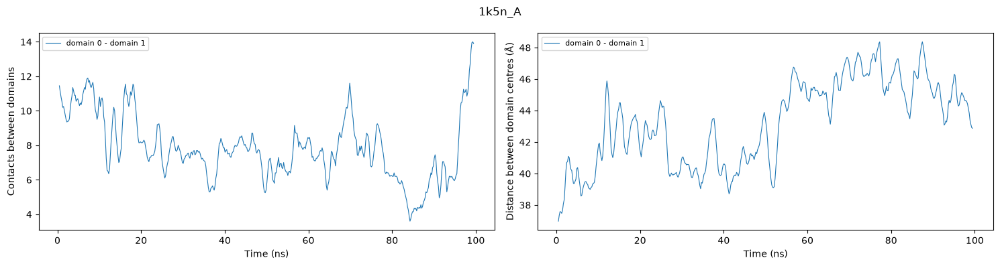

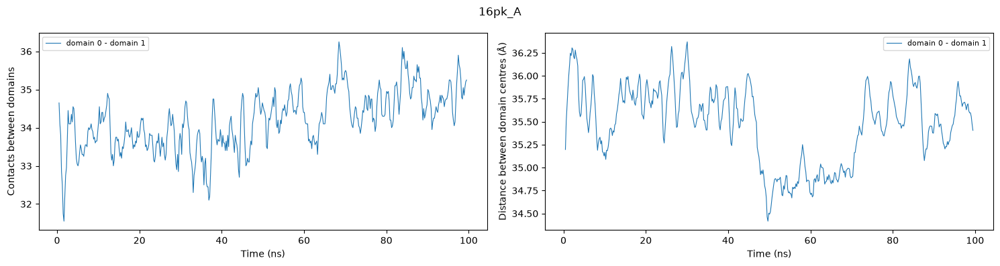

In [20]:
for p, d in domains.items():
    labels, names = d["labels"], d["names"]
    coords, t_raw = data[p]["coords"], data[p]["time_ns"]
    K = labels.max() + 1
    pairs = [(a, b) for a in range(K) for b in range(a + 1, K)]

    fig, axes = plt.subplots(1, 2, figsize=(15, 4))
    t = window_mean(t_raw)
    for a, b in pairs:
        ia, ib = np.flatnonzero(labels == a), np.flatnonzero(labels == b)
        n_contacts = np.array([(np.linalg.norm(f[ia][:, None] - f[ib][None], axis=-1) < CONTACT_THRESHOLD).sum()
                               for f in coords])
        centre_dist = np.linalg.norm(coords[:, ia].mean(1) - coords[:, ib].mean(1), axis=-1)
        axes[0].plot(t, window_mean(n_contacts), lw=0.8, label=f"{names[a]} - {names[b]}")
        axes[1].plot(t, window_mean(centre_dist), lw=0.8, label=f"{names[a]} - {names[b]}")
    axes[0].set_ylabel("Contacts between domains"); axes[1].set_ylabel("Distance between domain centres (Å)")
    for ax in axes:
        ax.set_xlabel("Time (ns)"); ax.legend(fontsize=8)
    fig.suptitle(p)
    plt.tight_layout()
    plt.show()

### Centrality per domain (optional combination of 1 and 3)

Betweenness is a natural fit for multi-domain proteins: residues at the domain interfaces carry the shortest paths between domains.
This plot shows each residue's betweenness over time with the domain boundaries marked; a hinge motion should show up as a change in the interface residues.

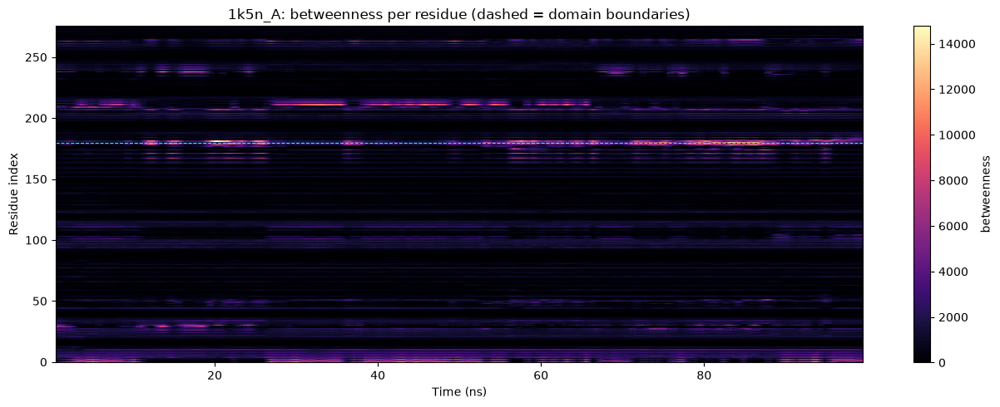

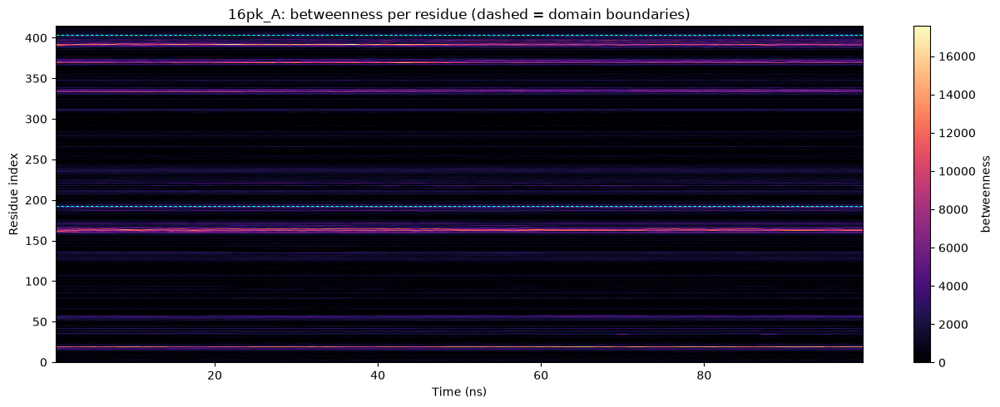

In [21]:
for p, d in domains.items():
    labels = d["labels"]
    X = window_mean(cent[p]["betweenness"])
    t = window_mean(data[p]["time_ns"])
    N = X.shape[1]
    fig, ax = plt.subplots(figsize=(13, 5))
    im = ax.imshow(X.T, aspect="auto", origin="lower", cmap="magma",
                   extent=[t[0], t[-1], -0.5, N - 0.5], interpolation="nearest")
    for b in np.flatnonzero(np.diff(labels)) + 0.5:
        ax.axhline(b, ls="--", lw=0.8, c="cyan")
    ax.set_xlabel("Time (ns)"); ax.set_ylabel("Residue index")
    ax.set_title(f"{p}: betweenness per residue (dashed = domain boundaries)")
    plt.colorbar(im, ax=ax, label="betweenness")
    plt.tight_layout()
    plt.show()

# 4 Feedbacks

### 4.1 t-SNE perplexity

**Why the t-SNE plots look like spaghetti.** t-SNE keeps each point next to its nearest neighbours. With overlapping windows, two consecutive windows share 16 of their 20 frames, so a window's nearest neighbours are almost always the windows just before and after it.
t-SNE then draws one long chain in time order: a thread, not clusters.

**Perplexity** is roughly the number of neighbours t-SNE pays attention to for each point (default 30). A larger perplexity makes each point consider more neighbours, including windows from other times in the same state, so states should come out as blobs instead of threads.
It must stay below about a third of the number of points.

The grid below tries perplexity 30, 100 and 300 on two inputs:
- the **1 ns windows with 0.8 overlap** (as in section 1, about 496 points),
- **single frames** without windows (2,001 points). Consecutive frames still look alike, but less so than overlapping windows.

**What to look for:** compact blobs that contain several time colours (a state the protein stays in or returns to), instead of a thread whose colour changes smoothly along its length.

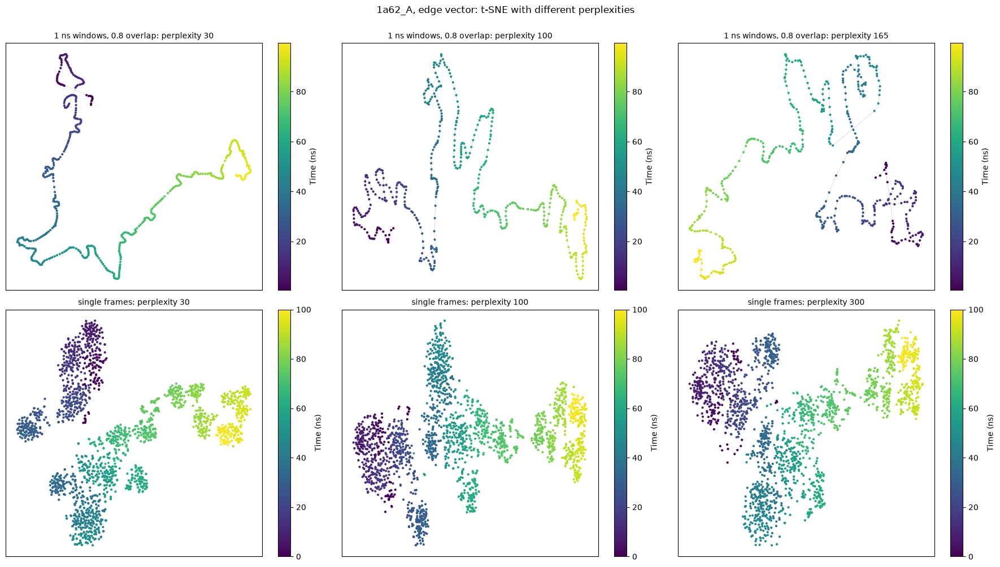

In [ ]:
PERPLEXITIES = [30, 100, 300]
TSNE_REPRESENTATION = "edge vector"      # or "betweenness", "degree", ...
p = PROTEIN

if TSNE_REPRESENTATION == "edge vector":
    single = changing_contacts(data[p]["coords"])
else:
    single = cent[p][TSNE_REPRESENTATION]

tsne_inputs = {
    "1 ns windows, 0.8 overlap": (window_mean(single), window_mean(data[p]["time_ns"])),
    "single frames": (single, data[p]["time_ns"]),
}

fig, axes = plt.subplots(len(tsne_inputs), len(PERPLEXITIES), figsize=(6 * len(PERPLEXITIES), 5 * len(tsne_inputs)))
for row, (name, (X, t)) in zip(axes, tsne_inputs.items()):
    X = X[:, varying_columns(X)]
    for ax, perp in zip(row, PERPLEXITIES):
        # capping the perplexity, below a third of the nr of points
        perp_used = min(perp, (len(X) - 1) // 3)
        # start from pca coordinates instead of random. more stable. 
        Y = TSNE(n_components=2, perplexity=perp_used, init="pca", random_state=RANDOM_STATE).fit_transform(X)
        plot_projection(ax, Y, t, f"{name}: perplexity {perp_used}", "Time (ns)", connect=(name != "single frames"))
fig.suptitle(f"{p}, {TSNE_REPRESENTATION}: t-SNE with different perplexities", y=1.0)
plt.tight_layout()
plt.show()

Perplexity doesn’t change the thread. Overlap only makes the path smoother: without overlap it’s still a path in time order (cell 47). The cause is slow drift in the contacts: each window is most similar to its time neighbours. Single frames form clumps because of frame-to-frame noise, but the clumps are still ordered in time.

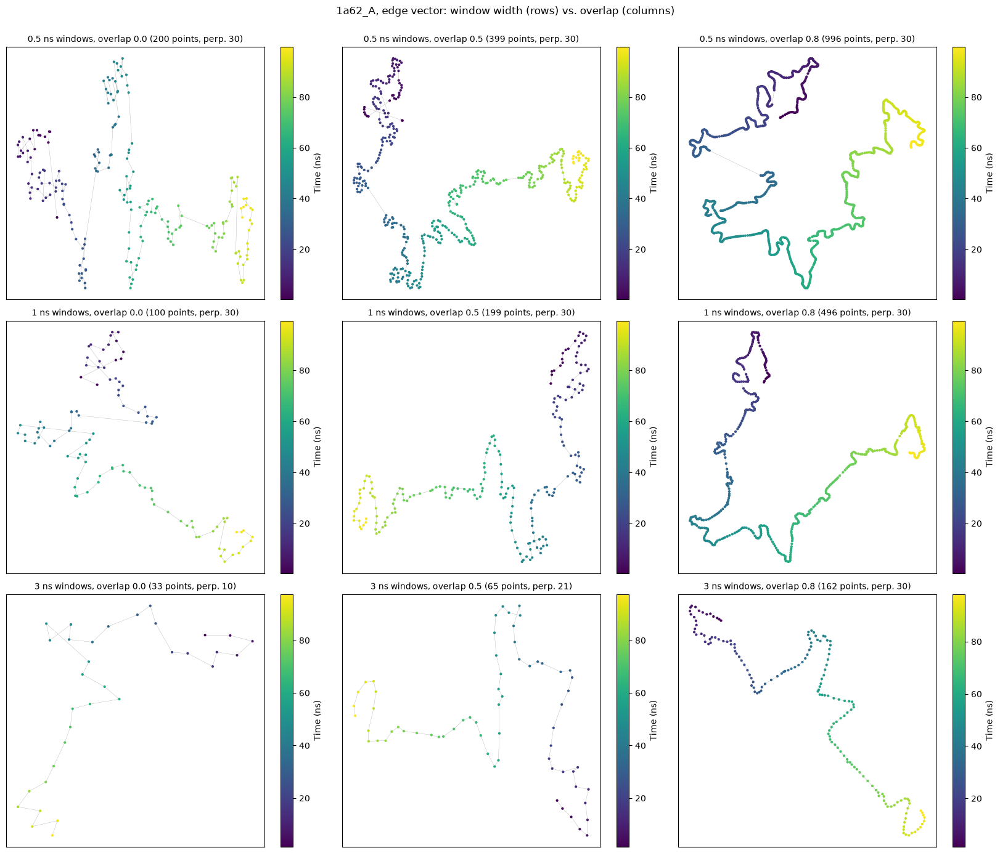

In [23]:
# Effect of window width and overlap on t-SNE (edge vector) for one protein
from sklearn.manifold import TSNE

PROTEIN = "1a62_A"
WIDTHS = [10, 20, 60]          # frames: 0.5 ns, 1 ns, 3 ns
OVERLAPS = [0.0, 0.5, 0.8]
FEATURE = "edge vector"        # or "betweenness"

frames = (contact_table(data[PROTEIN]["coords"]).astype(np.float32)
          if FEATURE == "edge vector" else cent[PROTEIN][FEATURE])
frames = frames[:, varying_columns(frames)]

fig, axes = plt.subplots(len(WIDTHS), len(OVERLAPS), figsize=(5.5 * len(OVERLAPS), 4.6 * len(WIDTHS)))
for i, w in enumerate(WIDTHS):
    for j, ov in enumerate(OVERLAPS):
        step = step_for(w, ov)
        X = window_mean(frames, width=w, step=step)
        t = window_mean(data[PROTEIN]["time_ns"], width=w, step=step)
        perp = min(30, (len(X) - 1) // 3)          # t-SNE needs perplexity < number of points
        Y = TSNE(n_components=2, perplexity=perp, init="pca",
                 random_state=RANDOM_STATE).fit_transform(X)
        plot_projection(axes[i, j], Y, t,
                        f"{w * 0.05:g} ns windows, overlap {ov} ({len(X)} points, perp. {perp})",
                        "Time (ns)")
fig.suptitle(f"{PROTEIN}, {FEATURE}: window width (rows) vs. overlap (columns)", y=1.0)
plt.tight_layout(); plt.show()

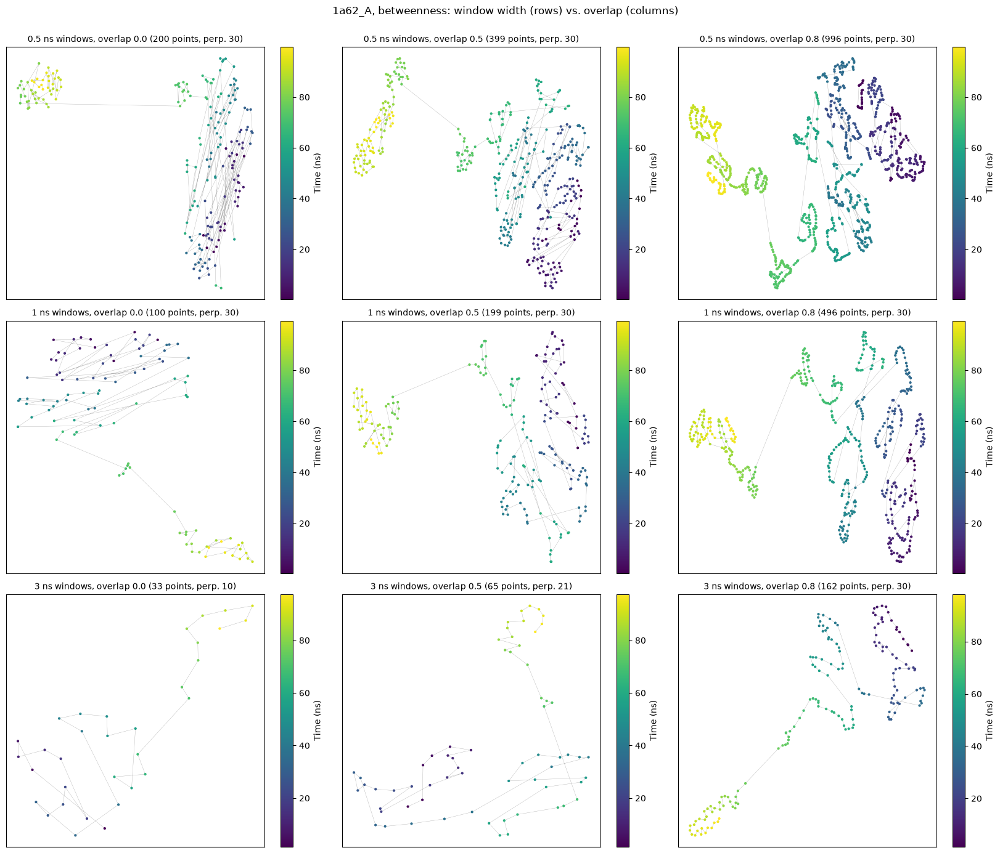

In [30]:
# Effect of window width and overlap on t-SNE (edge vector) for one protein
from sklearn.manifold import TSNE

PROTEIN = "1a62_A"
WIDTHS = [10, 20, 60]          # frames: 0.5 ns, 1 ns, 3 ns
OVERLAPS = [0.0, 0.5, 0.8]
FEATURE = "betweenness"        # or "betweenness"

frames = (contact_table(data[PROTEIN]["coords"]).astype(np.float32)
          if FEATURE == "edge vector" else cent[PROTEIN][FEATURE])
frames = frames[:, varying_columns(frames)]

fig, axes = plt.subplots(len(WIDTHS), len(OVERLAPS), figsize=(5.5 * len(OVERLAPS), 4.6 * len(WIDTHS)))
for i, w in enumerate(WIDTHS):
    for j, ov in enumerate(OVERLAPS):
        step = step_for(w, ov)
        X = window_mean(frames, width=w, step=step)
        t = window_mean(data[PROTEIN]["time_ns"], width=w, step=step)
        perp = min(30, (len(X) - 1) // 3)          # t-SNE needs perplexity < number of points
        Y = TSNE(n_components=2, perplexity=perp, init="pca",
                 random_state=RANDOM_STATE).fit_transform(X)
        plot_projection(axes[i, j], Y, t,
                        f"{w * 0.05:g} ns windows, overlap {ov} ({len(X)} points, perp. {perp})",
                        "Time (ns)")
fig.suptitle(f"{PROTEIN}, {FEATURE}: window width (rows) vs. overlap (columns)", y=1.0)
plt.tight_layout(); plt.show()

Edge vector: dominated by slow drift; the protein never returns to earlier contact patterns.
Betweenness: two stable regimes plus a short intermediate stage around 70–77 ns. Within the first regime the protein repeatedly revisits similar states.
Why the difference: centrality summarizes the network’s structure, so small contact changes that add up over time matter less. That makes centrality a better snapshot vector for finding states. 

### 4.2 Are there repetitions?

**The filtering cannot remove them.** Dropping constant columns removes residue pairs (or residues) that never change; it never removes frames.
Windowing averages neighbouring frames, but if the protein returned to an earlier state, the windows from that later time would still look like the earlier ones.
So if no returns show up, the data has none, or the 2D projection hides them.

Two checks, both in the **full feature space** (all contacts or all residues), not in the 2D projection, so the projection cannot hide anything:

1. **Identical snapshots.** How many frames have exactly the same contact pattern as another frame? This is what the paper's "same points" means: in the school data, every night snapshot was identical (no contacts at all). With 400+ flickering contacts, exact copies are unlikely in MD.
2. **Recurrence plot.** The distance between every pair of windows, drawn as an image with time on both axes (like the RMSD matrix). How to read it:
    - the **diagonal** is each window compared with itself (distance 0),
    - a **dark square block on the diagonal** = a stable state: all windows in that period resemble each other,
    - a **dark block away from the diagonal**, at (early time, late time) = a **return**: the late windows resemble the early ones,
    - if everything far from the diagonal is bright, the protein never comes back.

The right panel marks only the closest 10% of window pairs (black), which makes returns easier to spot.

In [ ]:
print("Identical contact snapshots (single frames, changing contacts only):")
for p in data:
    # full contact table, select only the changing contacts
    C = contact_table(data[p]["coords"])
    C = C[:, varying_columns(C)]
    # count unique rows (contact patterns) in the boolean table
    n_unique = len(np.unique(np.packbits(C, axis=1), axis=0))
    print(f"  {p}: {len(C)} frames, {n_unique} different contact patterns, {len(C) - n_unique} exact repeats")

Identical contact snapshots (single frames, changing contacts only):
  1a62_A: 2001 frames, 2001 different contact patterns, 0 exact repeats
  16pk_A: 2001 frames, 2001 different contact patterns, 0 exact repeats
  1k5n_A: 2001 frames, 2001 different contact patterns, 0 exact repeats


0 exact repeats. with hundreds of changing contacts, a few always flicker. 

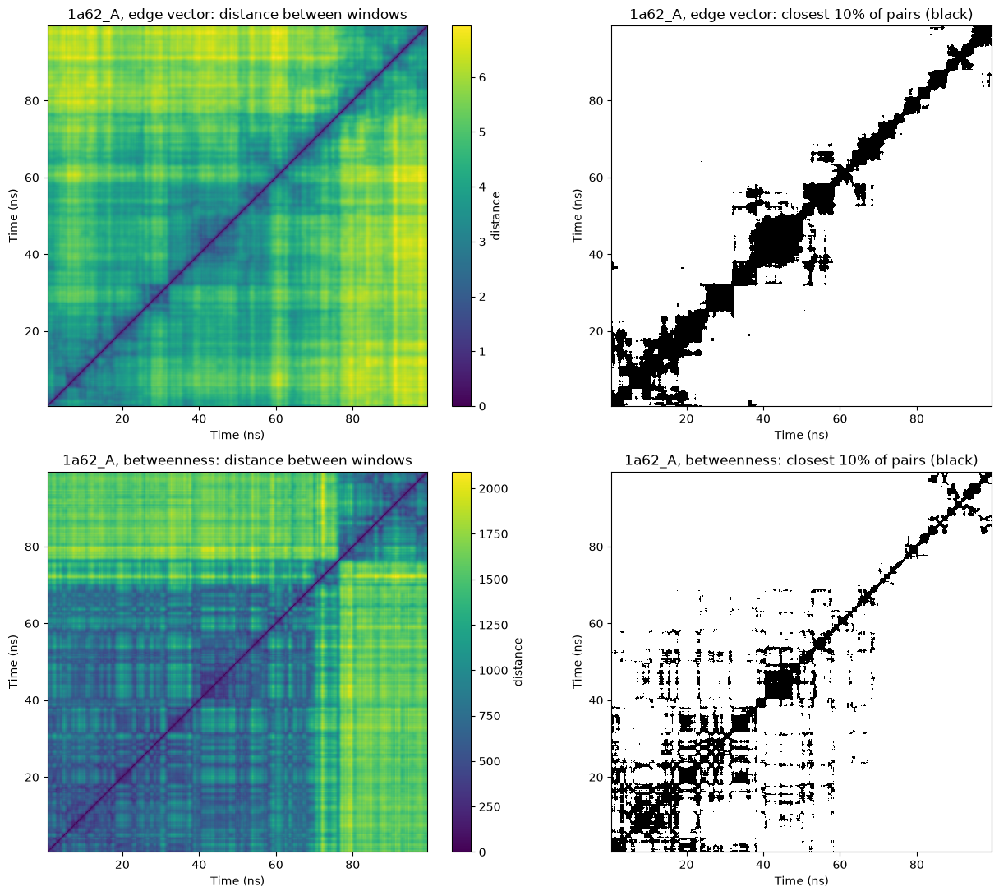

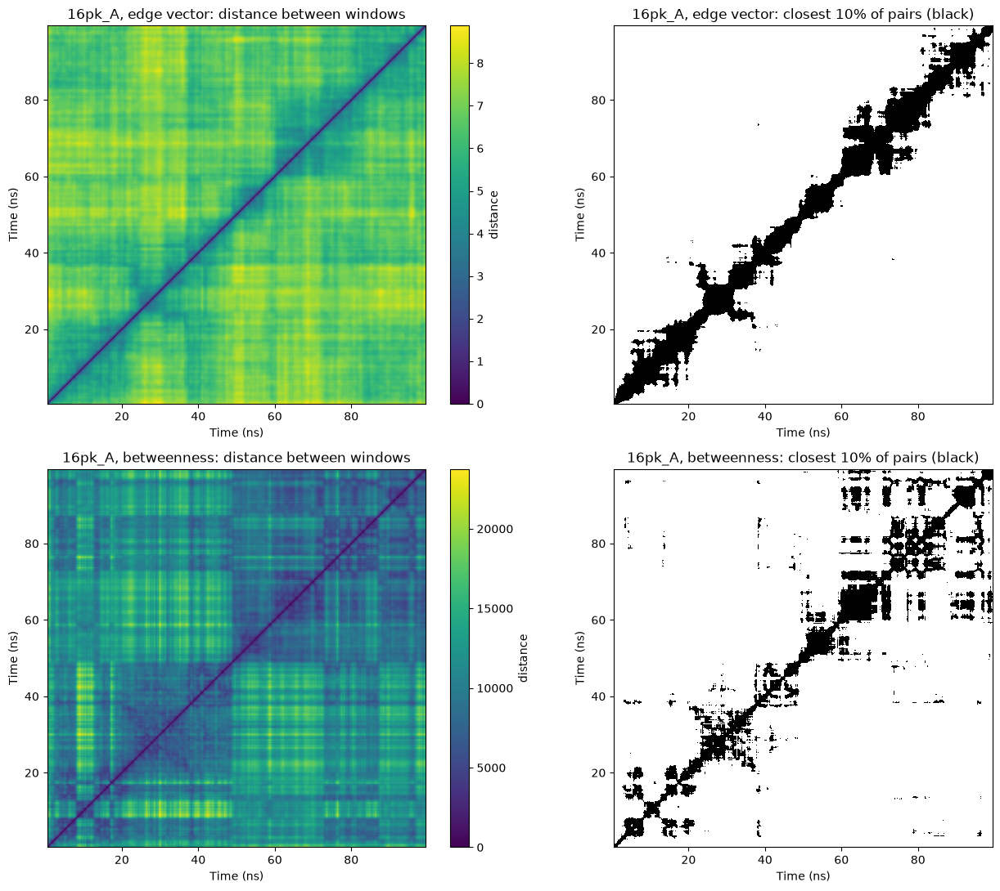

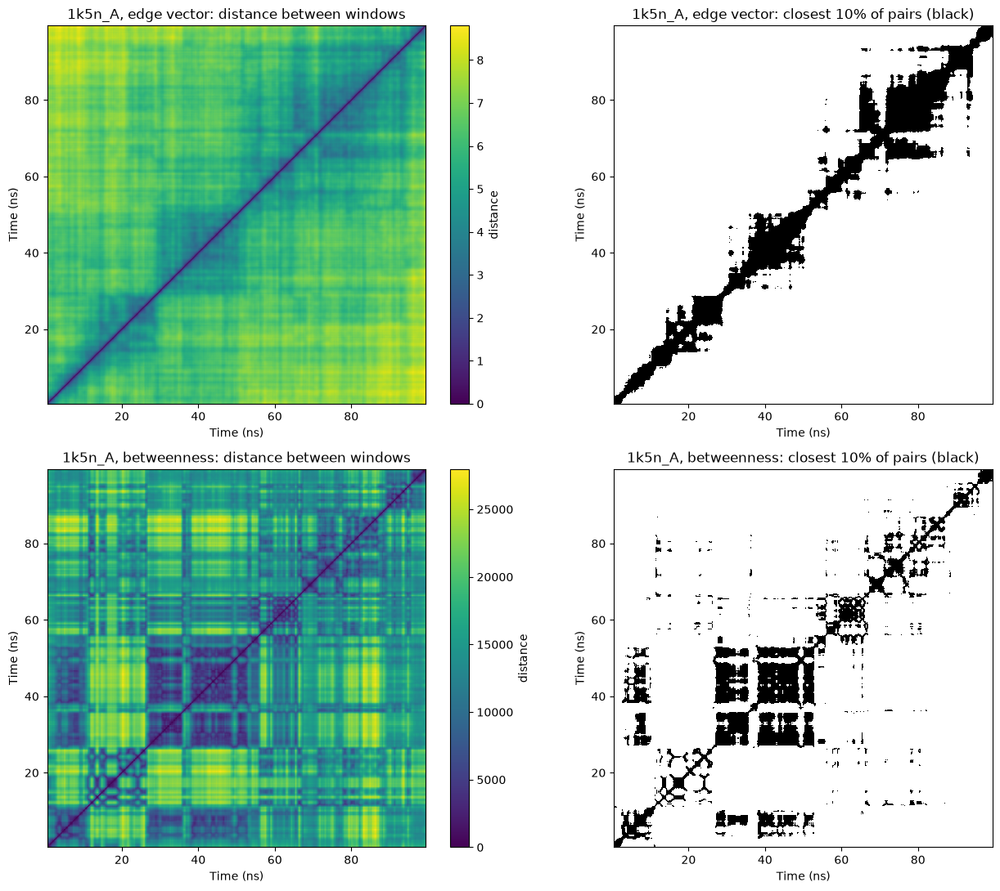

In [ ]:
RECURRENCE_REPRESENTATIONS = ["edge vector", "betweenness"]
CLOSEST_FRACTION = 0.10

for p in data:
    reps = representations(p)
    t = window_mean(data[p]["time_ns"])
    fig, axes = plt.subplots(len(RECURRENCE_REPRESENTATIONS), 2, figsize=(13, 5.5 * len(RECURRENCE_REPRESENTATIONS)),
                             squeeze=False)
    for row, rep in zip(axes, RECURRENCE_REPRESENTATIONS):
        X = reps[rep]
        X = X[:, varying_columns(X)]
        D = squareform(pdist(X))
        # distance below which the closest 10% of pairs fall (upper triangle only, no self-distances)
        eps = np.quantile(D[np.triu_indices(len(D), k=1)], CLOSEST_FRACTION)
        ext = [t[0], t[-1], t[0], t[-1]]
        im = row[0].imshow(D, origin="lower", cmap="viridis", extent=ext)
        row[0].set_title(f"{p}, {rep}: distance between windows")
        plt.colorbar(im, ax=row[0], label="distance")
        row[1].imshow(D < eps, origin="lower", cmap="Greys", extent=ext, interpolation="nearest")
        row[1].set_title(f"{p}, {rep}: closest {CLOSEST_FRACTION:.0%} of pairs (black)")
        for ax in row:
            ax.set_xlabel("Time (ns)"); ax.set_ylabel("Time (ns)")
    plt.tight_layout()
    plt.show()

### 4.3 mdCATH: why the shared projection looks odd

Two things in the section 2 plot are side effects of PCA, not features of the protein:

1. **The folded runs are squeezed into a thin streak.** PCA picks the directions with the most variation in the *whole* table. The 450 K run unfolds and changes hundreds of contacts, so it supplies almost all the variation.
   PC1 and PC2 end up describing the unfolding, and the differences between 320, 379 and 413 K (all folded) barely register.
2. **The 450 K run traces an arch.** When data changes gradually in one direction (here: steadily losing native contacts), PCA often draws a curve: PC1 follows the change and PC2 bends into a U shape: the middle of the change sits at one extreme of PC2, both ends at the other (the U can point up or down, since the sign of PC2 is arbitrary).
   This is a known artifact, called the **arch or horseshoe effect**. PC2 then adds no new information; it is just a curved function of PC1. So the "path up and around" should not be read as the protein visiting a separate region.

The middle plot (coloured by time) adds confusion: it colours four different runs on one time scale, so purple points from different temperatures look alike.

The cells below check and fix each point:
- **Variance per run:** how much of the total variation each run contributes.
- **Small multiples:** one panel per temperature in the same shared space, with the other runs in grey.
- **Arch check:** PC1 and PC2 against the fraction of native contacts Q. If PC1 follows Q and PC2 forms a U shape against Q, the arch is the horseshoe artifact.
- **PCA fitted on the folded runs only** (320–413 K): shows how the folded runs differ, and where 450 K leaves them.

In [26]:
FOLDED_TEMPS = [T for T in runs if T < 450]

# Contact tables and windows per run (full residue-pair table, so all runs share the same columns)
mC, mW, mt = {}, {}, {}
for T, r in runs.items():
    mC[T] = contact_table(r["coords"])
    mW[T] = window_mean(mC[T], MDCATH_WIDTH, mstep)
    mt[T] = window_mean(r["time_ns"], MDCATH_WIDTH, mstep)
keep_cols = varying_columns(np.vstack([mC[T] for T in runs]))
for T in runs:
    mW[T] = mW[T][:, keep_cols].astype(np.float32)
X_all = np.vstack([mW[T] for T in runs])
run_of = np.concatenate([np.full(len(mW[T]), T) for T in runs])

pca_all = PCA(n_components=2).fit(X_all)
Y_all = pca_all.transform(X_all)
print(f"Shared PCA: PC1 {pca_all.explained_variance_ratio_[0]:.0%}, PC2 {pca_all.explained_variance_ratio_[1]:.0%}")

centre = X_all.mean(axis=0)
total = ((X_all - centre) ** 2).sum()
print("Share of the total variation contributed by each run:")
for T in runs:
    share = ((X_all[run_of == T] - centre) ** 2).sum() / total
    print(f"  {T} K: {share:.0%}  ({(run_of == T).sum()} windows)")

Shared PCA: PC1 43%, PC2 5%
Share of the total variation contributed by each run:
  320 K: 14%  (496 windows)
  379 K: 4%  (126 windows)
  413 K: 16%  (496 windows)
  450 K: 66%  (496 windows)


One run dominates: the 450 K run supplies 66% of all variation. PCA puts its first axis where the variation is largest, so PC1 is the unfolding direction. PC1 correlates +1.00 with Q, the fraction of native contacts. In other words, PC1 is “how folded is it”.

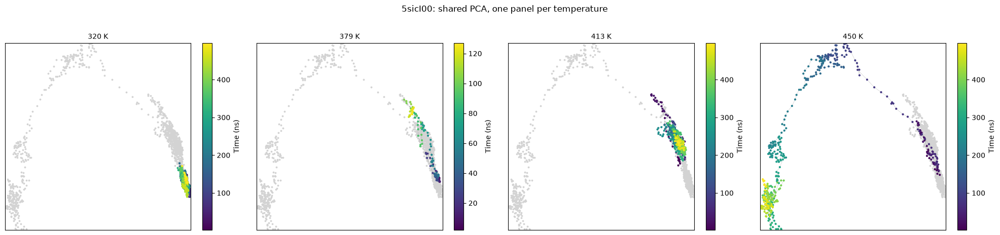

In [27]:
# Small multiples: each temperature in the shared space, the other runs in grey
lims = (Y_all[:, 0].min(), Y_all[:, 0].max()), (Y_all[:, 1].min(), Y_all[:, 1].max())
fig, axes = plt.subplots(1, len(runs), figsize=(5 * len(runs), 4.5))
for ax, T in zip(axes, runs):
    sel = run_of == T
    ax.scatter(Y_all[~sel, 0], Y_all[~sel, 1], s=3, c="lightgray")
    plot_projection(ax, Y_all[sel], mt[T], f"{T} K", "Time (ns)")
    ax.set_xlim(*lims[0]); ax.set_ylim(*lims[1])
fig.suptitle(f"{MDCATH_DOMAIN}: shared PCA, one panel per temperature", y=1.02)
plt.tight_layout()
plt.show()

214 native contacts (from the 320 K run)


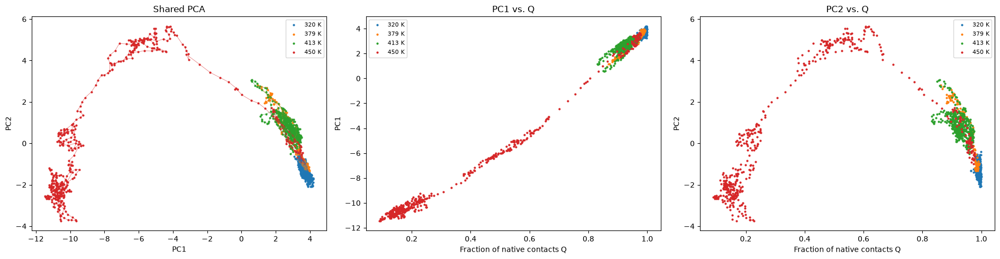

Correlation of PC1 with Q: +1.00


In [28]:
# Arch check: PC1 and PC2 against the fraction of native contacts Q
N_res = runs[FOLDED_TEMPS[0]]["coords"].shape[1]
I_all, J_all = np.triu_indices(N_res, k=1)
native = (mC[min(runs)].mean(axis=0) >= 0.9) & ((J_all - I_all) >= 3)     # contacts present in >= 90% of the coolest run
print(f"{native.sum()} native contacts (from the {min(runs)} K run)")
Q_all = np.concatenate([window_mean(mC[T][:, native].mean(axis=1), MDCATH_WIDTH, mstep) for T in runs])

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for T in runs:
    sel = run_of == T
    axes[0].plot(Y_all[sel, 0], Y_all[sel, 1], lw=0.5, alpha=0.7)
    axes[0].scatter(Y_all[sel, 0], Y_all[sel, 1], s=4, label=f"{T} K")
    axes[1].scatter(Q_all[sel], Y_all[sel, 0], s=4, label=f"{T} K")
    axes[2].scatter(Q_all[sel], Y_all[sel, 1], s=4, label=f"{T} K")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2"); axes[0].set_title("Shared PCA")
axes[1].set_xlabel("Fraction of native contacts Q"); axes[1].set_ylabel("PC1"); axes[1].set_title("PC1 vs. Q")
axes[2].set_xlabel("Fraction of native contacts Q"); axes[2].set_ylabel("PC2"); axes[2].set_title("PC2 vs. Q")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print(f"Correlation of PC1 with Q: {np.corrcoef(Q_all, Y_all[:, 0])[0, 1]:+.2f}")

PC2 vs. Q forms an arch peaking around Q ≈ 0.5. When data mainly follows one gradient, PCA often puts a curved version of that same gradient on PC2. So PC2 isn’t a second real process, and the large loop in the shared PCA isn’t a real path.

What happens at each temperature:
320 K, 379 K and 413 K all stay near the folded end in the shared PCA, so it can’t show differences between them.
450 K starts folded, unfolds step by step (passing through intermediate Q values around 0.4–0.7), and ends compact but non-native at Q ≈ 0.15. This matches what we found earlier.

Folded-only PCA: PC1 18%, PC2 11%


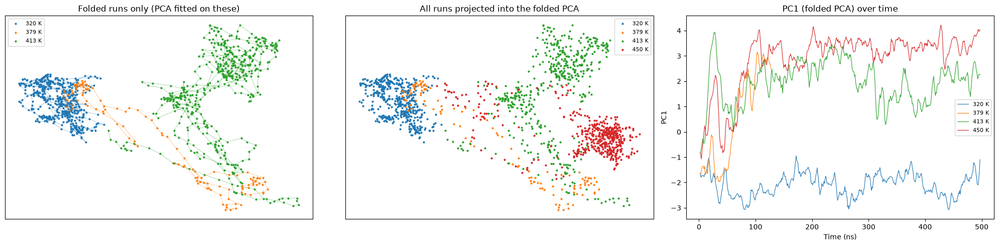

In [29]:
# PCA fitted on the folded runs only; every run projected into that space
X_fold = np.vstack([mW[T] for T in FOLDED_TEMPS])
pca_fold = PCA(n_components=2).fit(X_fold)
print(f"Folded-only PCA: PC1 {pca_fold.explained_variance_ratio_[0]:.0%}, PC2 {pca_fold.explained_variance_ratio_[1]:.0%}")

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for T in runs:
    Yt = pca_fold.transform(mW[T])
    if T in FOLDED_TEMPS:
        axes[0].plot(Yt[:, 0], Yt[:, 1], lw=0.4, alpha=0.7)
        axes[0].scatter(Yt[:, 0], Yt[:, 1], s=4, label=f"{T} K")
    axes[1].scatter(Yt[:, 0], Yt[:, 1], s=4, label=f"{T} K")
    axes[2].plot(mt[T], Yt[:, 0], lw=0.8, label=f"{T} K")
axes[0].set_title("Folded runs only (PCA fitted on these)")
axes[1].set_title("All runs projected into the folded PCA")
axes[2].set_title("PC1 (folded PCA) over time"); axes[2].set_xlabel("Time (ns)"); axes[2].set_ylabel("PC1")
for ax in axes[:2]:
    ax.set_xticks([]); ax.set_yticks([])
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

More balanced axes: PC1 18%, PC2 11%, instead of one axis taking everything. You can now see differences between the folded runs.
320 K stays in one region on the left.
413 K wanders the most and visits several sub-regions.
379 K moves from the 320 K region toward the lower right.
Over time: 379 K and 413 K both leave the starting region within about 50–100 ns, while 320 K stays put. Even at moderate temperatures the protein relaxes away from its starting structure. The 413 K run also has larger drops later, around 300 ns.
450 K in the folded PCA (red): don’t read much into it. The unfolded frames are far outside what this PCA was fitted on, so they’re squeezed into one area. Only the first part of that run, before unfolding, can be interpreted in this space.

Caveat: the 379 K run is only 126 windows long (it only contributes 4% of the variation), so its path is short.

What to report: when runs differ a lot (folded vs. unfolded), a single shared projection mostly shows the biggest difference and hides everything else. Two practical options are to fit the projection on a relevant subset (as done here), or to project each regime separately. This is a visualization point worth keeping in mind for your paper, because the same issue will show up when you compare whole-protein and per-domain projections.

# 5. Transition network

1a62_A silhouette: k=2: 0.51  k=3: 0.46  k=4: 0.35  k=5: 0.32  k=6: 0.27  k=7: 0.27  k=8: 0.26
16pk_A silhouette: k=2: 0.35  k=3: 0.28  k=4: 0.30  k=5: 0.29  k=6: 0.27  k=7: 0.28  k=8: 0.29
1k5n_A silhouette: k=2: 0.36  k=3: 0.34  k=4: 0.35  k=5: 0.35  k=6: 0.35  k=7: 0.34  k=8: 0.36


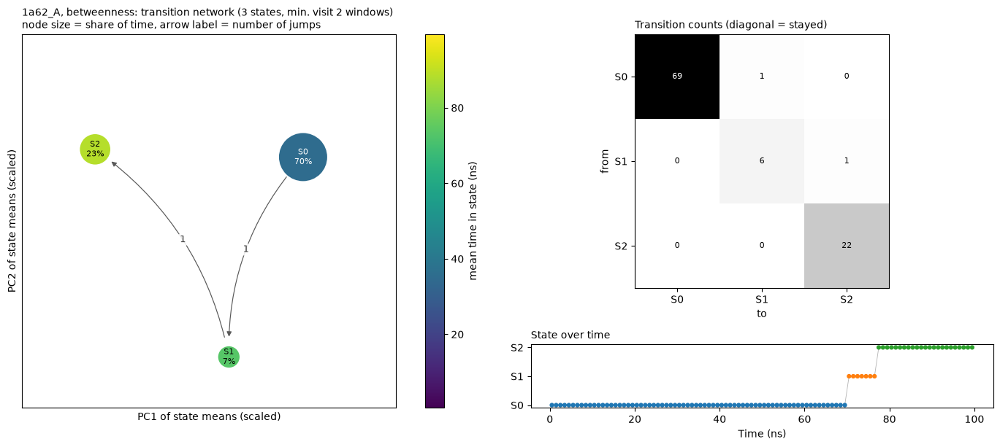

1a62_A: 3 states, 2 jumps between states, of which 0 are part of a back-and-forth pair (0%)


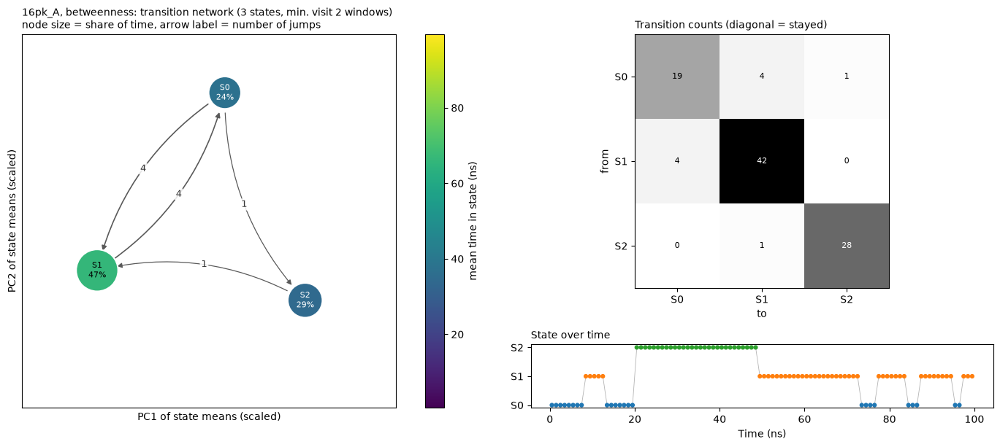

16pk_A: 3 states, 10 jumps between states, of which 8 are part of a back-and-forth pair (80%)


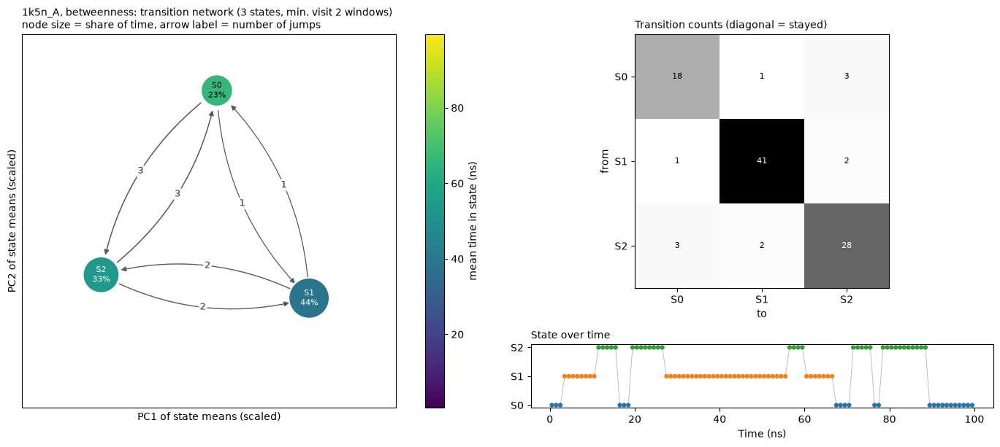

1k5n_A: 3 states, 12 jumps between states, of which 12 are part of a back-and-forth pair (100%)


In [ ]:
# ---- First transition networks: betweenness, 1 ns non-overlapping windows ----
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

TN_FEATURE = "betweenness"   # or "edge vector" to compare
TN_WIDTH = 20                # frames (1 ns)
TN_STEP = 20                 # = TN_WIDTH: no overlap, so every transition is counted once
TN_PCA = 10                  # reduce to this many PCA components before clustering
K_RANGE = range(2, 9)          # try 2-8 states
MIN_DWELL = 2               # visits shorter than this many windows are treated as noise (1 = keep everything)


# takes betweenness per frame and drops residues that don't change over time, 
# then averages over windows and does PCA
def tn_features(p):
    if TN_FEATURE == "edge vector":
        X = contact_table(data[p]["coords"]).astype(np.float32)
    else:
        X = cent[p][TN_FEATURE]
    X = X[:, varying_columns(X)]
    Xw = window_mean(X, width=TN_WIDTH, step=TN_STEP)
    tw = window_mean(data[p]["time_ns"], width=TN_WIDTH, step=TN_STEP)
    Z = PCA(n_components=min(TN_PCA, len(Xw) - 1), random_state=RANDOM_STATE).fit_transform(Xw)
    return Z, tw

# k-means clustering of the PCA-reduced features, 
# tries 20 different starts and keeps the best one
# renumbering the states by first appearance in time
def cluster_states(Z, k):
    labels = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(Z)
    # renumber states by first appearance in time: S0 is where the run starts
    order = {old: new for new, old in enumerate(dict.fromkeys(labels))}
    return np.array([order[l] for l in labels])

# walks through the state sequence window by window 
# and counts how many times each transition occurs (from state a to state b)
def transition_counts(states, k):
    T = np.zeros((k, k), dtype=int)
    for a, b in zip(states[:-1], states[1:]):
        T[a, b] += 1
    return T

# removing flickers: if a state is visited for less than min_dwell windows, 
# it is merged into the previous state
def remove_short_visits(states, min_dwell):
    """Merge visits shorter than min_dwell windows into the state before them (removes 1-window flickers)."""
    s = states.copy()
    if min_dwell <= 1:
        return s
    i = 0
    while i < len(s):
        j = i
        while j < len(s) and s[j] == s[i]:
            j += 1
        if j - i < min_dwell and i > 0:
            s[i:j] = s[i - 1]
        i = j
    return s

# node pos = mean of the PCA coordinates of all windows in that state
# node size = share of time spent in that state
# node color = mean time spent in that state
# arrow = jumps, labelled with how many times they happened
def draw_transition_network(ax, Z, states, tw, T, title):
    k = T.shape[0]
    pos = np.array([Z[states == s, :2].mean(axis=0) for s in range(k)])
    pos = (pos - pos.mean(axis=0)) / (np.ptp(pos, axis=0) + 1e-9)       # same scale on both axes
    occ = np.bincount(states, minlength=k) / len(states)
    mean_t = np.array([tw[states == s].mean() for s in range(k)])
    norm = plt.Normalize(tw.min(), tw.max())
    for a in range(k):
        for b in range(k):
            if a != b and T[a, b] > 0:
                ax.annotate("", xy=pos[b], xytext=pos[a], zorder=1,
                            arrowprops=dict(arrowstyle="-|>", color="0.35", lw=0.8 + 4 * T[a, b] / T.max(),
                                            shrinkA=20, shrinkB=20, connectionstyle="arc3,rad=0.2"))
                d = pos[b] - pos[a]
                normal = np.array([d[1], -d[0]]) / (np.linalg.norm(d) + 1e-9)
                mid = (pos[a] + pos[b]) / 2 + 0.1 * np.linalg.norm(d) * normal
                ax.text(*mid, str(T[a, b]), fontsize=9, color="0.2", ha="center", va="center",
                        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85), zorder=4)
    ax.scatter(pos[:, 0], pos[:, 1], s=300 + 3000 * occ, c=plt.cm.viridis(norm(mean_t)),
               edgecolors="white", linewidths=1.5, zorder=2)
    for s in range(k):
        ax.text(*pos[s], f"S{s}\n{occ[s]:.0%}", ha="center", va="center", fontsize=8,
                color="white" if norm(mean_t[s]) < 0.6 else "black", zorder=3)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlabel("PC1 of state means (scaled)"); ax.set_ylabel("PC2 of state means (scaled)")
    ax.set_xlim(-0.9, 0.9); ax.set_ylim(-0.9, 0.9); ax.set_aspect("equal")
    plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="viridis"), ax=ax, label="mean time in state (ns)")


# 1) how many states? silhouette score per k (higher = better separated clusters)
# between -1 to 1, measures how clearly separated the clusters are. 0 = overlapping, 1 = well-separated, -1 = mislabelled
tn = {}
for p in cent:
    Z, tw = tn_features(p)
    scores = {k: silhouette_score(Z, cluster_states(Z, k)) for k in K_RANGE}
    tn[p] = {"Z": Z, "tw": tw, "scores": scores}
    print(p, "silhouette:", "  ".join(f"k={k}: {s:.2f}" for k, s in scores.items()))
# ---- Pick the number of states per protein and draw the networks ----
N_STATES = {p: 3 for p in tn}     # 2 states always look back-and-forth; 3+ shows real structure
# N_STATES["1a62_A"] = 4

for p in tn:
    Z, tw, k = tn[p]["Z"], tn[p]["tw"], N_STATES[p]
    states = remove_short_visits(cluster_states(Z, k), MIN_DWELL)
    T = transition_counts(states, k)
    tn[p].update(states=states, T=T)

    fig = plt.figure(figsize=(15, 6.2))
    gs = fig.add_gridspec(2, 2, width_ratios=[1.25, 1], height_ratios=[4, 1])
    ax_net = fig.add_subplot(gs[:, 0])
    ax_mat = fig.add_subplot(gs[0, 1])
    ax_strip = fig.add_subplot(gs[1, 1])

    draw_transition_network(ax_net, Z, states, tw, T,
                            f"{p}, {TN_FEATURE}: transition network ({k} states, min. visit {MIN_DWELL} windows)\n"
                            "node size = share of time, arrow label = number of jumps")

    im = ax_mat.imshow(T, cmap="Greys")
    for a in range(k):
        for b in range(k):
            ax_mat.text(b, a, T[a, b], ha="center", va="center", fontsize=8,
                        color="white" if T[a, b] > T.max() / 2 else "black")
    ax_mat.set_xticks(range(k), [f"S{s}" for s in range(k)]); ax_mat.set_yticks(range(k), [f"S{s}" for s in range(k)])
    ax_mat.set_xlabel("to"); ax_mat.set_ylabel("from")
    ax_mat.set_title("Transition counts (diagonal = stayed)", loc="left", fontsize=10)

    ax_strip.scatter(tw, states, c=states, cmap="tab10", vmin=0, vmax=9, s=12)
    ax_strip.plot(tw, states, color="0.7", lw=0.6, zorder=0)
    ax_strip.set_yticks(range(k), [f"S{s}" for s in range(k)])
    ax_strip.set_xlabel("Time (ns)"); ax_strip.set_title("State over time", loc="left", fontsize=10)
    plt.tight_layout(); plt.show()

    off = T.sum() - np.trace(T)
    back = sum(min(T[a, b], T[b, a]) for a in range(k) for b in range(a + 1, k))
    print(f"{p}: {k} states, {off} jumps between states, of which {2 * back} are part of a back-and-forth pair "
          f"({2 * back / max(off, 1):.0%})")

1a62_A silhouette: k=2: 0.37  k=3: 0.31  k=4: 0.35  k=5: 0.40  k=6: 0.38  k=7: 0.40  k=8: 0.41
16pk_A silhouette: k=2: 0.23  k=3: 0.25  k=4: 0.31  k=5: 0.36  k=6: 0.40  k=7: 0.40  k=8: 0.40
1k5n_A silhouette: k=2: 0.31  k=3: 0.34  k=4: 0.34  k=5: 0.39  k=6: 0.41  k=7: 0.43  k=8: 0.43


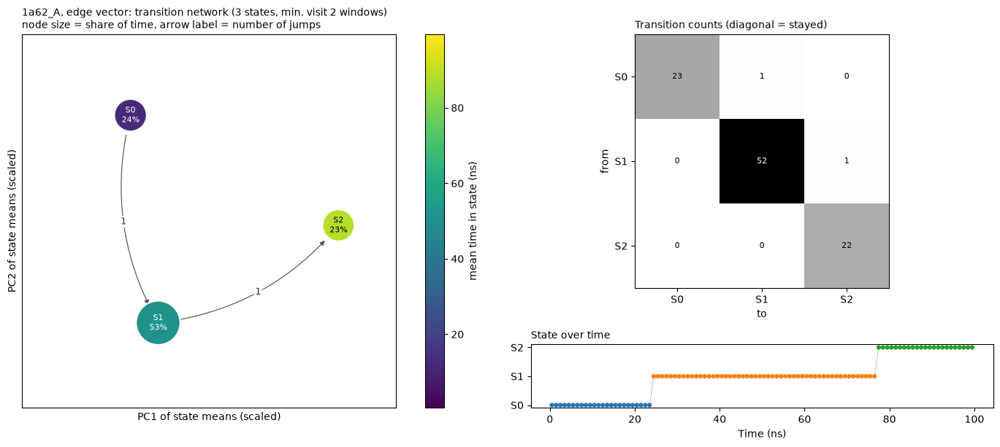

1a62_A: 3 states, 2 jumps between states, of which 0 are part of a back-and-forth pair (0%)


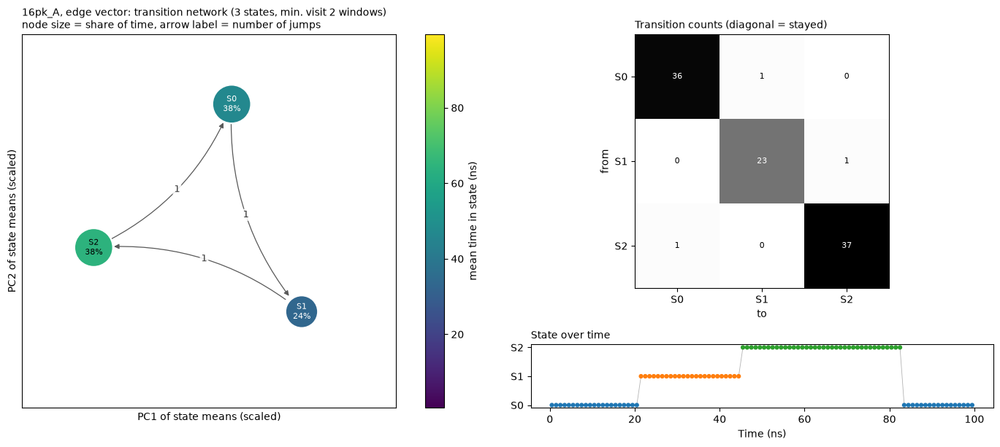

16pk_A: 3 states, 3 jumps between states, of which 0 are part of a back-and-forth pair (0%)


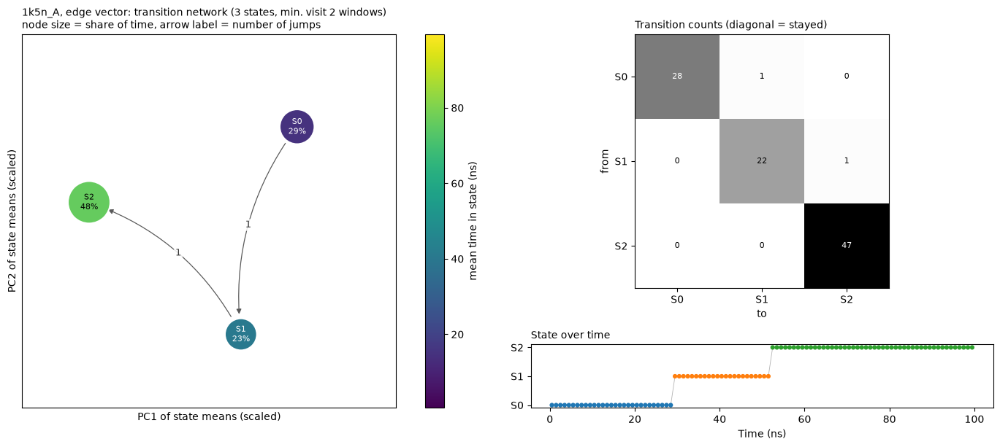

1k5n_A: 3 states, 2 jumps between states, of which 0 are part of a back-and-forth pair (0%)


In [ ]:
# ---- First transition networks: contacts, 1 ns non-overlapping windows ----
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

TN_FEATURE = "edge vector"   
TN_WIDTH = 20                # frames (1 ns)
TN_STEP = 20                 # = TN_WIDTH: no overlap, so every transition is counted once
TN_PCA = 10                  # reduce to this many PCA components before clustering
K_RANGE = range(2, 9)
MIN_DWELL = 2               # visits shorter than this many windows are treated as noise (1 = keep everything)


def tn_features(p):
    if TN_FEATURE == "edge vector":
        X = contact_table(data[p]["coords"]).astype(np.float32)
    else:
        X = cent[p][TN_FEATURE]
    X = X[:, varying_columns(X)]
    Xw = window_mean(X, width=TN_WIDTH, step=TN_STEP)
    tw = window_mean(data[p]["time_ns"], width=TN_WIDTH, step=TN_STEP)
    Z = PCA(n_components=min(TN_PCA, len(Xw) - 1), random_state=RANDOM_STATE).fit_transform(Xw)
    return Z, tw


def cluster_states(Z, k):
    labels = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(Z)
    # renumber states by first appearance in time: S0 is where the run starts
    order = {old: new for new, old in enumerate(dict.fromkeys(labels))}
    return np.array([order[l] for l in labels])


def transition_counts(states, k):
    T = np.zeros((k, k), dtype=int)
    for a, b in zip(states[:-1], states[1:]):
        T[a, b] += 1
    return T


def remove_short_visits(states, min_dwell):
    """Merge visits shorter than min_dwell windows into the state before them (removes 1-window flickers)."""
    s = states.copy()
    if min_dwell <= 1:
        return s
    i = 0
    while i < len(s):
        j = i
        while j < len(s) and s[j] == s[i]:
            j += 1
        if j - i < min_dwell and i > 0:
            s[i:j] = s[i - 1]
        i = j
    return s


def draw_transition_network(ax, Z, states, tw, T, title):
    k = T.shape[0]
    pos = np.array([Z[states == s, :2].mean(axis=0) for s in range(k)])
    pos = (pos - pos.mean(axis=0)) / (np.ptp(pos, axis=0) + 1e-9)       # same scale on both axes
    occ = np.bincount(states, minlength=k) / len(states)
    mean_t = np.array([tw[states == s].mean() for s in range(k)])
    norm = plt.Normalize(tw.min(), tw.max())
    for a in range(k):
        for b in range(k):
            if a != b and T[a, b] > 0:
                ax.annotate("", xy=pos[b], xytext=pos[a], zorder=1,
                            arrowprops=dict(arrowstyle="-|>", color="0.35", lw=0.8 + 4 * T[a, b] / T.max(),
                                            shrinkA=20, shrinkB=20, connectionstyle="arc3,rad=0.2"))
                d = pos[b] - pos[a]
                normal = np.array([d[1], -d[0]]) / (np.linalg.norm(d) + 1e-9)
                mid = (pos[a] + pos[b]) / 2 + 0.1 * np.linalg.norm(d) * normal
                ax.text(*mid, str(T[a, b]), fontsize=9, color="0.2", ha="center", va="center",
                        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85), zorder=4)
    ax.scatter(pos[:, 0], pos[:, 1], s=300 + 3000 * occ, c=plt.cm.viridis(norm(mean_t)),
               edgecolors="white", linewidths=1.5, zorder=2)
    for s in range(k):
        ax.text(*pos[s], f"S{s}\n{occ[s]:.0%}", ha="center", va="center", fontsize=8,
                color="white" if norm(mean_t[s]) < 0.6 else "black", zorder=3)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlabel("PC1 of state means (scaled)"); ax.set_ylabel("PC2 of state means (scaled)")
    ax.set_xlim(-0.9, 0.9); ax.set_ylim(-0.9, 0.9); ax.set_aspect("equal")
    plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="viridis"), ax=ax, label="mean time in state (ns)")


# 1) how many states? silhouette score per k (higher = better separated clusters)
tn = {}
for p in cent:
    Z, tw = tn_features(p)
    scores = {k: silhouette_score(Z, cluster_states(Z, k)) for k in K_RANGE}
    tn[p] = {"Z": Z, "tw": tw, "scores": scores}
    print(p, "silhouette:", "  ".join(f"k={k}: {s:.2f}" for k, s in scores.items()))
# ---- Pick the number of states per protein and draw the networks ----
N_STATES = {p: 3 for p in tn}     # 2 states always look back-and-forth; 3+ shows real structure
# N_STATES["1a62_A"] = 4

for p in tn:
    Z, tw, k = tn[p]["Z"], tn[p]["tw"], N_STATES[p]
    states = remove_short_visits(cluster_states(Z, k), MIN_DWELL)
    T = transition_counts(states, k)
    tn[p].update(states=states, T=T)

    fig = plt.figure(figsize=(15, 6.2))
    gs = fig.add_gridspec(2, 2, width_ratios=[1.25, 1], height_ratios=[4, 1])
    ax_net = fig.add_subplot(gs[:, 0])
    ax_mat = fig.add_subplot(gs[0, 1])
    ax_strip = fig.add_subplot(gs[1, 1])

    draw_transition_network(ax_net, Z, states, tw, T,
                            f"{p}, {TN_FEATURE}: transition network ({k} states, min. visit {MIN_DWELL} windows)\n"
                            "node size = share of time, arrow label = number of jumps")

    im = ax_mat.imshow(T, cmap="Greys")
    for a in range(k):
        for b in range(k):
            ax_mat.text(b, a, T[a, b], ha="center", va="center", fontsize=8,
                        color="white" if T[a, b] > T.max() / 2 else "black")
    ax_mat.set_xticks(range(k), [f"S{s}" for s in range(k)]); ax_mat.set_yticks(range(k), [f"S{s}" for s in range(k)])
    ax_mat.set_xlabel("to"); ax_mat.set_ylabel("from")
    ax_mat.set_title("Transition counts (diagonal = stayed)", loc="left", fontsize=10)

    ax_strip.scatter(tw, states, c=states, cmap="tab10", vmin=0, vmax=9, s=12)
    ax_strip.plot(tw, states, color="0.7", lw=0.6, zorder=0)
    ax_strip.set_yticks(range(k), [f"S{s}" for s in range(k)])
    ax_strip.set_xlabel("Time (ns)"); ax_strip.set_title("State over time", loc="left", fontsize=10)
    plt.tight_layout(); plt.show()

    off = T.sum() - np.trace(T)
    back = sum(min(T[a, b], T[b, a]) for a in range(k) for b in range(a + 1, k))
    print(f"{p}: {k} states, {off} jumps between states, of which {2 * back} are part of a back-and-forth pair "
          f"({2 * back / max(off, 1):.0%})")

Contacts give chains; betweenness gives cycles. But both find the same moments of change.

1k5n_A: contacts that change at least once -> domain 1: 524, domain 2: 258, interface: 73


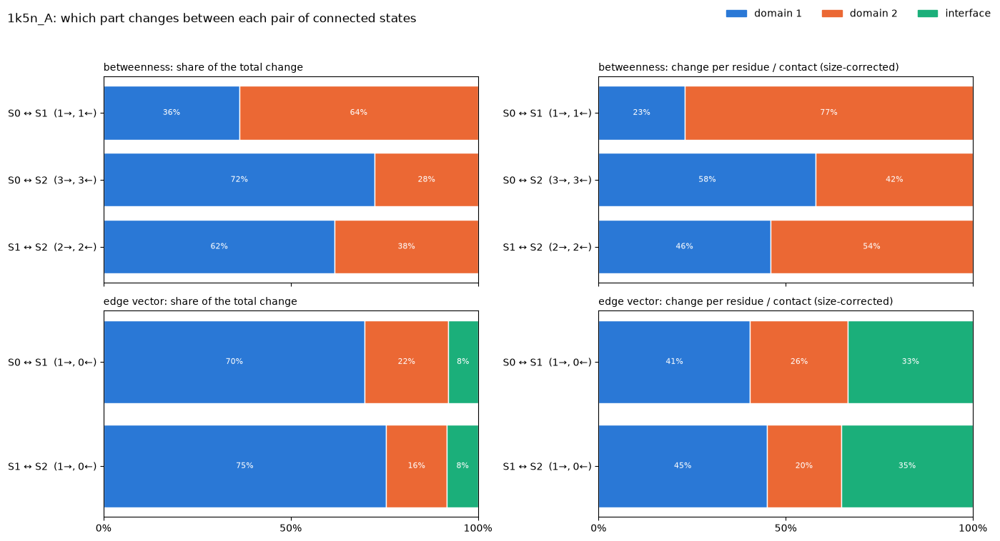

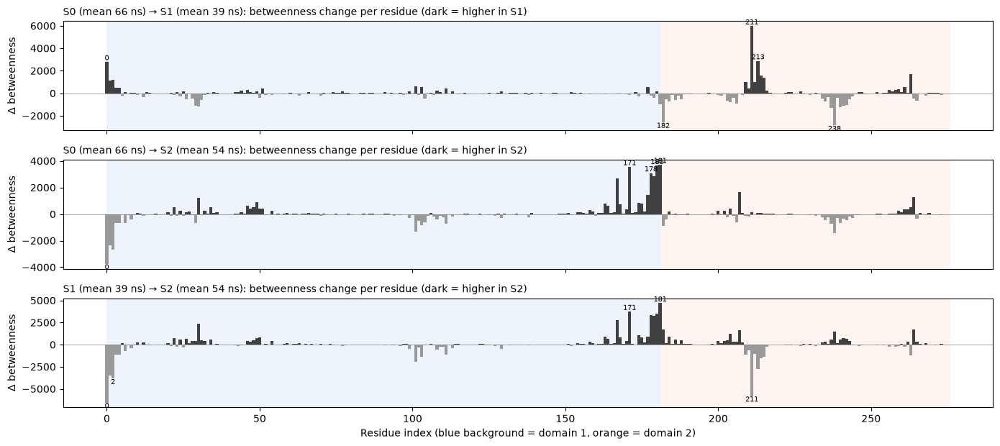

1k5n_A, betweenness: states (first–last visit) -> S0 0-99 ns, S1 3-66 ns, S2 11-88 ns
1k5n_A, edge vector: states (first–last visit) -> S0 0-28 ns, S1 29-51 ns, S2 52-99 ns
16pk_A: contacts that change at least once -> domain 1: 660, domain 2: 622, interface: 49


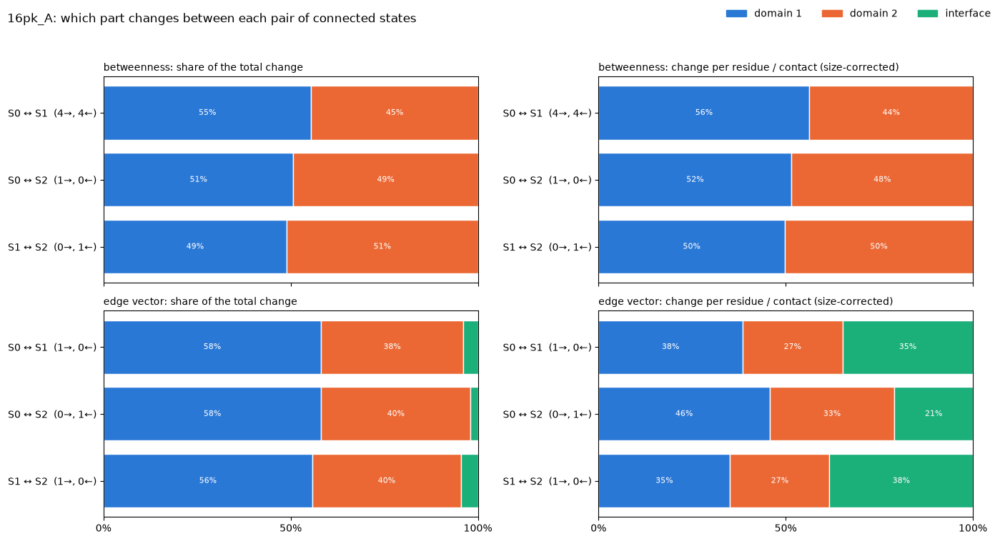

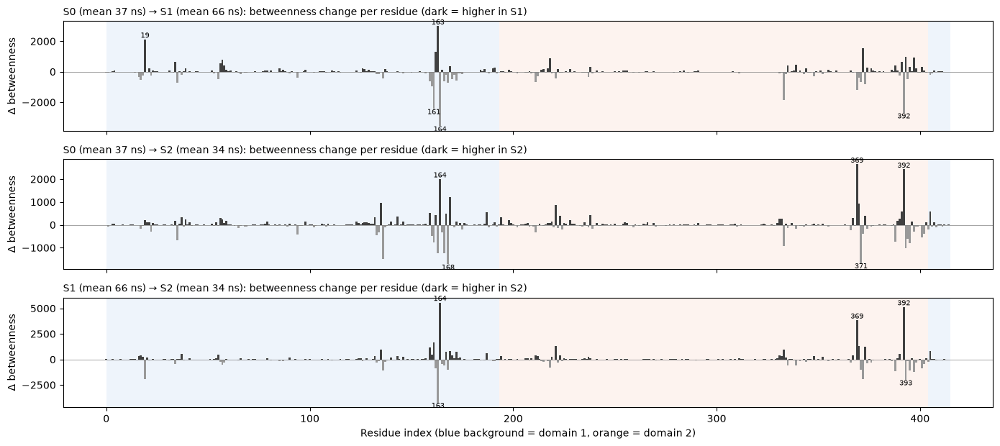

16pk_A, betweenness: states (first–last visit) -> S0 0-96 ns, S1 8-99 ns, S2 20-48 ns
16pk_A, edge vector: states (first–last visit) -> S0 0-99 ns, S1 21-44 ns, S2 45-82 ns


In [ ]:
# ---- Which domain drives each transition? ----
# Domain boundaries from CATH (0-based residue indices, end exclusive), as in part 3 / part 4
DOMAINS = {
    "1k5n_A": {"domain 1": [(0, 181)], "domain 2": [(181, 276)]},
    "16pk_A": {"domain 1": [(0, 193), (404, 415)], "domain 2": [(193, 404)]},
}
ATTR_STATES = {"1k5n_A": 3, "16pk_A": 3}      # number of states per protein (same as the networks above)
PART_COLOURS = {"domain 1": "#2a78d6", "domain 2": "#eb6834", "interface": "#1baf7a"}

# gives every residue a domain label
def residue_domains(p, N):
    """Array of length N with 0 = domain 1, 1 = domain 2, -1 = not assigned."""
    lab = np.full(N, -1)
    for d, name in enumerate(["domain 1", "domain 2"]):
        for a, b in DOMAINS[p][name]:
            lab[a:min(b, N)] = d
    return lab

# recomputes the states for both betweenness and edge vector, 
# then counts the jumps between states and attributes the change to the domains or interface
def states_for(p, feature, k):
    """Cluster the 1 ns windows of one feature into k states (same pipeline as the network cells)."""
    global TN_FEATURE
    old, TN_FEATURE = TN_FEATURE, feature
    Z, tw = tn_features(p)
    TN_FEATURE = old
    states = remove_short_visits(cluster_states(Z, k), MIN_DWELL)
    return Z, tw, states

# computes each residue's average value in each state
# then takes the difference
def state_pairs(states, k):
    """Pairs of states (a < b) with at least one jump between them, plus the jump counts each way."""
    T = transition_counts(states, k)
    return [(a, b, T[a, b], T[b, a]) for a in range(k) for b in range(a + 1, k) if T[a, b] + T[b, a] > 0], T

# add up the differences of all residues in domain 1, in domain 2,
# and at the interface, then normalise by the total change
def attribution(diff, part_of):
    """diff: absolute change per residue or contact; part_of: part name per residue/contact
    (use "none" for columns to ignore). Returns raw share of the total change and mean change
    per residue/contact, for each part."""
    parts = [n for n in PART_COLOURS if (part_of == n).any()]
    raw = {n: diff[part_of == n].sum() for n in parts}
    total = sum(raw.values()) or 1.0
    per_unit = {n: diff[part_of == n].mean() for n in parts}
    return {n: raw[n] / total for n in parts}, per_unit


def stacked_bar(ax, rows, title):
    """rows: list of (label, {part: value}); values are normalised per row so each bar sums to 1."""
    for i, (label, vals) in enumerate(rows):
        left, tot = 0.0, sum(vals.values()) or 1.0
        for n, v in vals.items():
            ax.barh(i, v / tot, left=left, color=PART_COLOURS[n], edgecolor="white")
            if v / tot > 0.08:
                ax.text(left + v / tot / 2, i, f"{v / tot:.0%}", ha="center", va="center", fontsize=8, color="white")
            left += v / tot
    ax.set_yticks(range(len(rows)), [r[0] for r in rows]); ax.invert_yaxis()
    ax.set_xlim(0, 1); ax.set_xticks([0, 0.5, 1], ["0%", "50%", "100%"])
    ax.set_title(title, loc="left", fontsize=10)


attr = {}
for p in DOMAINS:
    N = data[p]["coords"].shape[1]
    res_dom = residue_domains(p, N)
    res_part = np.array(["domain 1", "domain 2", "none"])[res_dom]
    I, J = np.triu_indices(N, k=1)
    con_part = np.where(res_dom[I] != res_dom[J], "interface", res_part[I])
    con_part[(res_dom[I] < 0) | (res_dom[J] < 0)] = "none"
    k = ATTR_STATES[p]

    # per-window values (1 ns, no overlap), same windows as the networks
    B = window_mean(cent[p]["betweenness"], width=TN_WIDTH, step=TN_STEP)                       # windows x residues
    C = window_mean(contact_table(data[p]["coords"]).astype(np.float32), width=TN_WIDTH, step=TN_STEP)  # windows x contacts

    attr[p] = {}
    # only count contacts that actually form at some point: residue pairs that are never in contact
    # would otherwise dilute the per-contact average (especially for the interface)
    con_part_active = np.where(C.std(axis=0) > 0, con_part, "none")
    print(f"{p}: contacts that change at least once ->",
          ", ".join(f"{n}: {(con_part_active == n).sum()}" for n in PART_COLOURS))

    for feature, values, part_of in [("betweenness", B, res_part), ("edge vector", C, con_part_active)]:
        Z, tw, states = states_for(p, feature, k)
        pairs, T = state_pairs(states, k)
        means = np.array([values[states == s].mean(axis=0) for s in range(k)])
        rows_raw, rows_unit = [], []
        for a, b, nab, nba in pairs:
            raw, unit = attribution(np.abs(means[b] - means[a]), part_of)
            label = f"S{a} ↔ S{b}  ({nab}→, {nba}←)"
            rows_raw.append((label, raw)); rows_unit.append((label, unit))
        attr[p][feature] = dict(states=states, tw=tw, means=means, pairs=pairs, raw=rows_raw, unit=rows_unit)

    # ---- figure 1: attribution bars, both features ----
    fig, axes = plt.subplots(2, 2, figsize=(14, 2.2 + 0.9 * max(len(attr[p][f]["pairs"]) for f in attr[p]) * 2),
                             sharex=True)
    for row, feature in enumerate(["betweenness", "edge vector"]):
        A = attr[p][feature]
        stacked_bar(axes[row, 0], A["raw"], f"{feature}: share of the total change")
        stacked_bar(axes[row, 1], A["unit"], f"{feature}: change per residue / contact (size-corrected)")
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in PART_COLOURS.values()]
    fig.legend(handles, PART_COLOURS.keys(), loc="upper right", ncol=3, frameon=False)
    fig.suptitle(f"{p}: which part changes between each pair of connected states", x=0.01, ha="left")
    plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

    # ---- figure 2: per-residue betweenness change for each pair, domains shaded ----
    A = attr[p]["betweenness"]
    fig, axes = plt.subplots(len(A["pairs"]), 1, figsize=(14, 2.1 * len(A["pairs"])), sharex=True, squeeze=False)
    for ax, (a, b, nab, nba) in zip(axes[:, 0], A["pairs"]):
        for name in ["domain 1", "domain 2"]:
            for lo, hi in DOMAINS[p][name]:
                ax.axvspan(lo, min(hi, N), color=PART_COLOURS[name], alpha=0.08, lw=0)
        d = A["means"][b] - A["means"][a]
        ax.bar(np.arange(N), d, width=1.0, color=np.where(d > 0, "0.25", "0.6"))
        ax.axhline(0, color="0.5", lw=0.5)
        ta = A["tw"][A["states"] == a].mean(); tb = A["tw"][A["states"] == b].mean()
        ax.set_title(f"S{a} (mean {ta:.0f} ns) → S{b} (mean {tb:.0f} ns): betweenness change per residue "
                     f"(dark = higher in S{b})", loc="left", fontsize=10)
        ax.set_ylabel("Δ betweenness")
        top = np.argsort(-np.abs(d))[:5]
        for r in top:
            ax.annotate(str(r), (r, d[r]), fontsize=7, ha="center", va="bottom" if d[r] > 0 else "top")
    axes[-1, 0].set_xlabel("Residue index (blue background = domain 1, orange = domain 2)")
    plt.tight_layout(); plt.show()

    for feature in ["betweenness", "edge vector"]:
        A = attr[p][feature]
        print(f"{p}, {feature}: states (first–last visit) ->",
              ", ".join(f"S{s} {A['tw'][A['states'] == s].min():.0f}-{A['tw'][A['states'] == s].max():.0f} ns"
                        for s in range(k)))

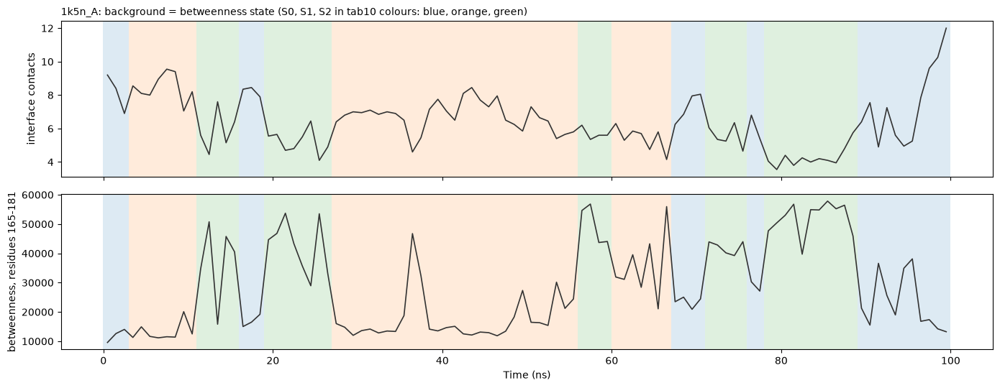

S0: mean interface contacts 7.5, mean hinge betweenness 21344
S1: mean interface contacts 6.8, mean hinge betweenness 19704
S2: mean interface contacts 5.1, mean hinge betweenness 45740
correlation interface contacts vs hinge betweenness: -0.81


In [ ]:
# ---- Test the hinge idea for 1k5n_A: interface contacts and hinge betweenness over time ----
P = "1k5n_A"
HINGE = (165, 182)          # residues around the domain boundary that gain betweenness in S2
N = data[P]["coords"].shape[1]
res_dom = residue_domains(P, N)
I, J = np.triu_indices(N, k=1)
# picks the residue pairs between domain 1 and 2. 
is_interface = (res_dom[I] >= 0) & (res_dom[J] >= 0) & (res_dom[I] != res_dom[J])

# compute the interface contacts and hinge betweenness over time, then plot them
frames_ct = contact_table(data[P]["coords"])
iface = window_mean(frames_ct[:, is_interface].sum(axis=1).astype(float), width=TN_WIDTH, step=TN_STEP)
hinge = window_mean(cent[P]["betweenness"][:, HINGE[0]:HINGE[1]].sum(axis=1), width=TN_WIDTH, step=TN_STEP)
A = attr[P]["betweenness"]
tw, states = A["tw"], A["states"]

fig, axes = plt.subplots(2, 1, figsize=(14, 5.5), sharex=True)
for ax, y, lab in [(axes[0], iface, "interface contacts"), (axes[1], hinge, f"betweenness, residues {HINGE[0]}-{HINGE[1] - 1}")]:
    for s in range(states.max() + 1):
        for t in tw[states == s]:
            ax.axvspan(t - 0.5, t + 0.5, color=plt.cm.tab10(s), alpha=0.15, lw=0)
    ax.plot(tw, y, color="0.2", lw=1.2)
    ax.set_ylabel(lab)
axes[0].set_title(f"{P}: background = betweenness state (" +
                  ", ".join(f"S{s}" for s in range(states.max() + 1)) + " in tab10 colours: blue, orange, green)",
                  loc="left", fontsize=10)
axes[1].set_xlabel("Time (ns)")
plt.tight_layout(); plt.show()

for s in range(states.max() + 1):
    print(f"S{s}: mean interface contacts {iface[states == s].mean():.1f}, mean hinge betweenness {hinge[states == s].mean():.0f}")
print(f"correlation interface contacts vs hinge betweenness: {np.corrcoef(iface, hinge)[0, 1]:+.2f}")

# 6. Replicas

R2: 2001 frames, computing betweenness ...
R3: 2001 frames, computing betweenness ...
replicas used: ['R1', 'R2', 'R3']

state   interface  hinge btw   share of time per replica
S0           11.0      11723   R1:   4%  R2: 100%  R3:  75%
S1            7.0      20006   R1:  60%  R2:   0%  R3:   0%
S2            5.3      44045   R1:  36%  R2:   0%  R3:  25%

correlation interface contacts vs hinge betweenness, per replica: R1: -0.81  R2: -0.18  R3: -0.83
R1: 11 jumps between states
R2: 0 jumps between states
R3: 8 jumps between states


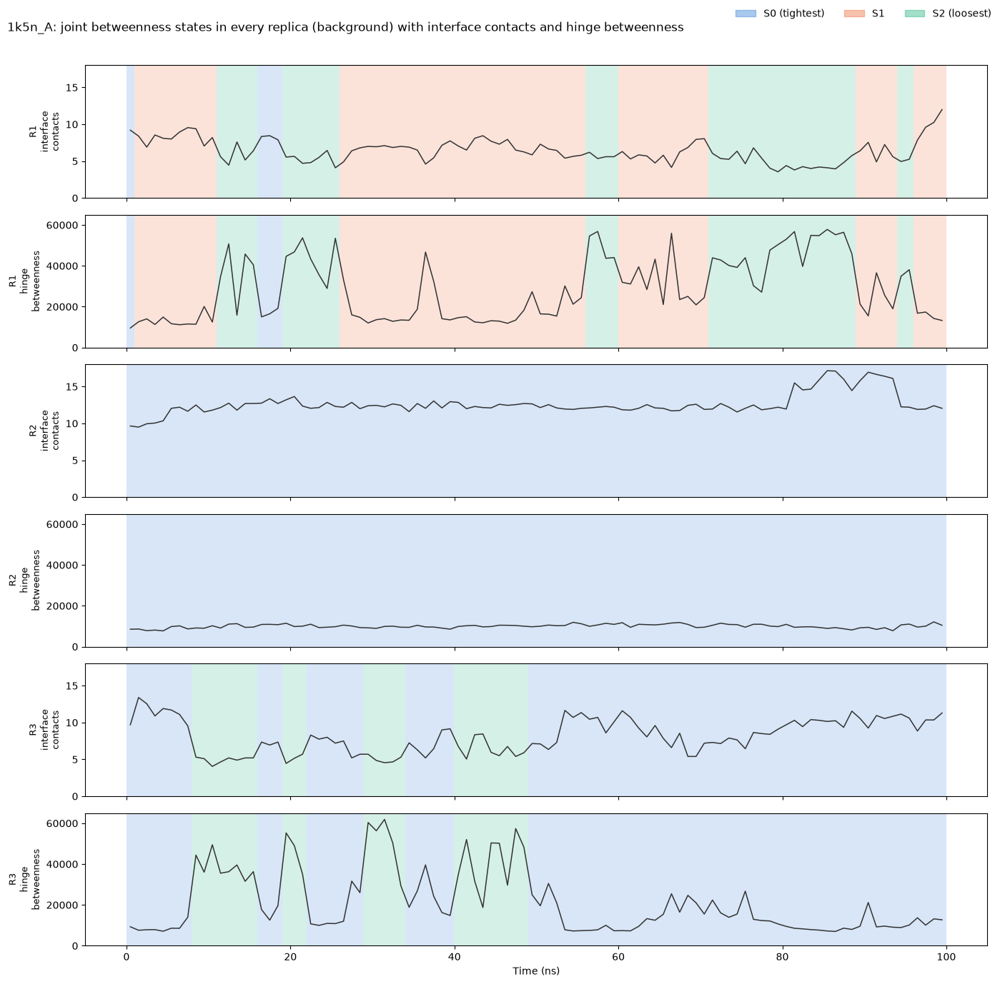

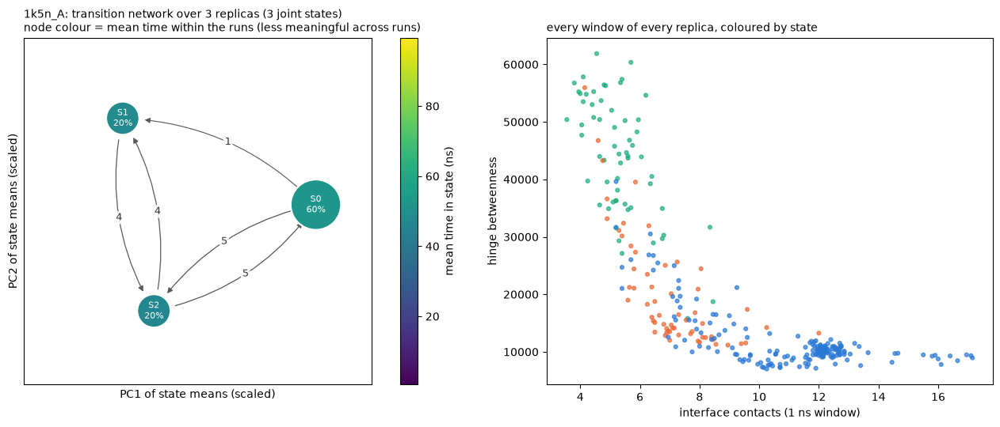

transition counts summed over replicas (rows = from, columns = to):
 [[171   1   5]
 [  0  55   4]
 [  5   4  52]]


In [ ]:
# ---- Replicas: does the tight/loose switching of 1k5n_A come back in R2 and R3? ----
# ATLAS provides three independent 100 ns runs per protein (R1, R2, R3), usually in the same folder.
import os
from scipy.spatial.distance import cdist

P = "1k5n_A"
REPLICAS = ["R1", "R2", "R3"]
K_REP = 3                  # number of joint states
HINGE = (165, 182)         # residues 165-181


def replica_path(protein, rep):
    folder = f"{protein}_protein"
    return f"{folder}/{protein}.pdb", f"{folder}/{protein}_prod_{rep}_fit.xtc"


def load_replica(protein, rep, stride=STRIDE):
    pdb, xtc = replica_path(protein, rep)
    traj = md.load(xtc, top=pdb, stride=stride)
    traj = traj.atom_slice(traj.topology.select("name CA"))
    return {"coords": traj.xyz * 10, "time_ns": traj.time / 1000}


def betweenness_only(coords, threshold=CONTACT_THRESHOLD):
    """Betweenness per residue per frame (faster than computing all four centralities)."""
    out = []
    for f in coords:
        A = squareform(pdist(f) < threshold)
        i, j = np.nonzero(np.triu(A, k=1))
        g = ig.Graph(n=len(f), edges=list(zip(i.tolist(), j.tolist())))
        out.append(g.betweenness())
    return np.array(out, dtype=float)


# 1) load every replica and 
# compute betweenness + interface contacts per frame
N = data[P]["coords"].shape[1]
dom = residue_domains(P, N)
d1, d2 = np.where(dom == 0)[0], np.where(dom == 1)[0]
reps = {}
for r in REPLICAS:
    if r == "R1":
        d = {"coords": data[P]["coords"], "time_ns": data[P]["time_ns"]}
        btw = cent[P]["betweenness"]
    else:
        if not os.path.exists(replica_path(P, r)[1]):
            print(f"{r}: file {replica_path(P, r)[1]} not found, skipped")
            continue
        d = load_replica(P, r)
        print(f"{r}: {len(d['coords'])} frames, computing betweenness ...")
        btw = betweenness_only(d["coords"])
    iface = np.array([(cdist(f[d1], f[d2]) < CONTACT_THRESHOLD).sum() for f in d["coords"]], dtype=float)
    reps[r] = {
        "tw": window_mean(d["time_ns"], width=TN_WIDTH, step=TN_STEP),
        "B": window_mean(btw, width=TN_WIDTH, step=TN_STEP),
        "iface": window_mean(iface, width=TN_WIDTH, step=TN_STEP),
        "hinge": window_mean(btw[:, HINGE[0]:HINGE[1]].sum(axis=1), width=TN_WIDTH, step=TN_STEP),
    }
print("replicas used:", list(reps))

# 2) joint states: one PCA + k-means over the windows of all replicas, 
# so state S1 means the same in every run
Ball = np.vstack([reps[r]["B"] for r in reps])
Ball = Ball[:, varying_columns(Ball)]
Zall = PCA(n_components=TN_PCA, random_state=RANDOM_STATE).fit_transform(Ball)
raw = KMeans(n_clusters=K_REP, n_init=20, random_state=RANDOM_STATE).fit_predict(Zall)
iface_all = np.concatenate([reps[r]["iface"] for r in reps])

# number the states from tight to loose: S0 = most interface contacts
order = np.argsort([-iface_all[raw == s].mean() for s in range(K_REP)])
relabel = {old: new for new, old in enumerate(order)}
raw = np.array([relabel[s] for s in raw])

start = 0
T_all = np.zeros((K_REP, K_REP), dtype=int)
for r in reps:
    n = len(reps[r]["tw"])
    reps[r]["Z"] = Zall[start:start + n]
    reps[r]["states"] = remove_short_visits(raw[start:start + n], MIN_DWELL)   # flicker filter per run
    T_all += transition_counts(reps[r]["states"], K_REP)                        # no jumps across runs
    start += n
states_all = np.concatenate([reps[r]["states"] for r in reps])
hinge_all = np.concatenate([reps[r]["hinge"] for r in reps])

# 3) summary table: does every replica visit the same states, 
# and do they mean the same?
print(f"\n{'state':6}{'interface':>11}{'hinge btw':>11}   share of time per replica")
for s in range(K_REP):
    shares = "  ".join(f"{r}: {np.mean(reps[r]['states'] == s):4.0%}" for r in reps)
    print(f"S{s:<5}{iface_all[states_all == s].mean():11.1f}{hinge_all[states_all == s].mean():11.0f}   {shares}")
print("\ncorrelation interface contacts vs hinge betweenness, per replica:",
      "  ".join(f"{r}: {np.corrcoef(reps[r]['iface'], reps[r]['hinge'])[0, 1]:+.2f}" for r in reps))
for r in reps:
    st = reps[r]["states"]
    print(f"{r}: {np.sum(st[1:] != st[:-1])} jumps between states")

# 4) timelines: one block per replica 
# (interface contacts and hinge betweenness, state as background)
STATE_COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#8a5cd1", "#d1495b"]
fig, axes = plt.subplots(2 * len(reps), 1, figsize=(14, 2.3 * 2 * len(reps)), sharex=True)
for i, r in enumerate(reps):
    R = reps[r]
    for ax, y, lab in [(axes[2 * i], R["iface"], "interface\ncontacts"),
                       (axes[2 * i + 1], R["hinge"], "hinge\nbetweenness")]:
        for t, s in zip(R["tw"], R["states"]):
            ax.axvspan(t - 0.5, t + 0.5, color=STATE_COLOURS[s], alpha=0.18, lw=0)
        ax.plot(R["tw"], y, color="0.2", lw=1.1)
        ax.set_ylabel(f"{r}\n{lab}", fontsize=9)
    axes[2 * i].set_ylim(0, iface_all.max() * 1.05)
    axes[2 * i + 1].set_ylim(0, hinge_all.max() * 1.05)
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLOURS[s], alpha=0.4) for s in range(K_REP)]
fig.legend(handles, [f"S{s}" + (" (tightest)" if s == 0 else " (loosest)" if s == K_REP - 1 else "") for s in range(K_REP)],
           loc="upper right", ncol=K_REP, frameon=False)
fig.suptitle(f"{P}: joint betweenness states in every replica (background) with interface contacts and hinge betweenness",
             x=0.01, ha="left")
axes[-1].set_xlabel("Time (ns)")
plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

# 5) one transition network for all replicas together
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
draw_transition_network(axes[0], Zall, states_all, np.concatenate([reps[r]["tw"] for r in reps]), T_all,
                        f"{P}: transition network over {len(reps)} replicas ({K_REP} joint states)\n"
                        "node colour = mean time within the runs (less meaningful across runs)")
axes[1].scatter(iface_all, hinge_all, c=[STATE_COLOURS[s] for s in states_all], s=12, alpha=0.7)
axes[1].set_xlabel("interface contacts (1 ns window)"); axes[1].set_ylabel("hinge betweenness")
axes[1].set_title("every window of every replica, coloured by state", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
print("transition counts summed over replicas (rows = from, columns = to):\n", T_all)

C:\Users\bella\AppData\Local\Temp\ipykernel_24924\4220406620.py:79: RuntimeWarning: Mean of empty slice
  return np.nanmean(np.abs(W - base), axis=1)


9 entries into the loose state: R1 at 11.1 ns, R1 at 18.9 ns, R1 at 56.0 ns, R1 at 70.9 ns, R1 at 92.6 ns, R3 at 8.0 ns, R3 at 18.6 ns, R3 at 26.8 ns, R3 at 40.4 ns


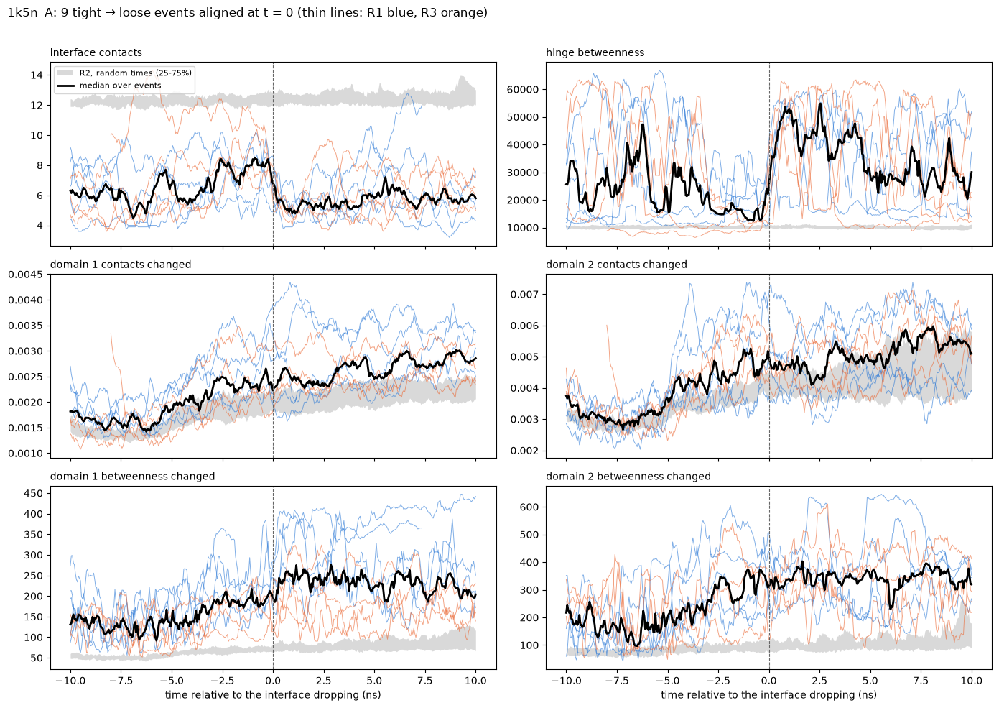

'interface contacts' changes clearly in only 2/9 events: not drawn
'hinge betweenness' changes clearly in only 3/9 events: not drawn
'domain 1 contacts changed' changes clearly in only 3/9 events: not drawn
'domain 2 contacts changed' changes clearly in only 2/9 events: not drawn


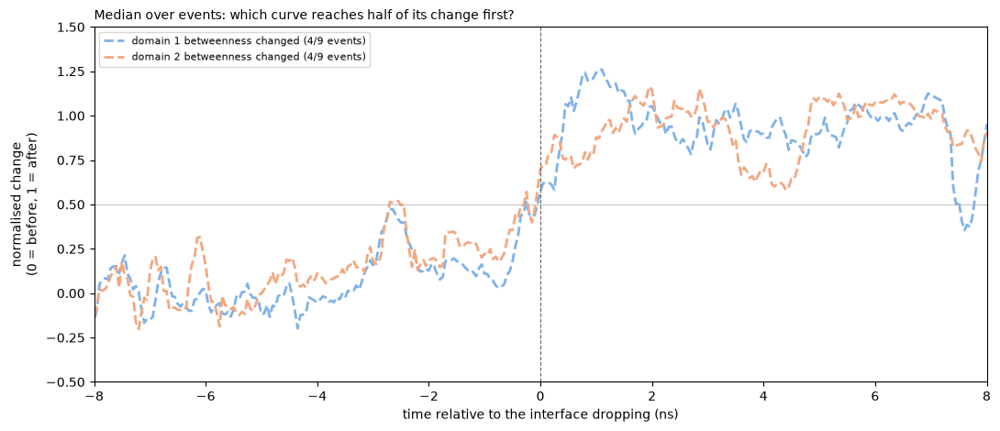


Time (ns) at which each signal reaches half of its change, per event (negative = before t = 0);
nan = this signal does not clearly change in that event
event             interface contacts     hinge betweenness     domain 1 contacts     domain 2 contacts  domain 1 betweenness  domain 2 betweenness
R1   11.1 ns                     nan                   0.1                  -2.7                   nan                   0.1                  -0.4
R1   18.9 ns                     nan                   nan                   nan                  -4.5                   nan                   nan
R1   56.0 ns                     nan                  -0.0                   0.6                   nan                  -0.1                   0.0
R1   70.9 ns                     nan                   nan                   nan                   nan                   nan                  -4.8
R1   92.6 ns                    -5.0                   nan                   nan                  -4.8          

In [41]:
# ---- Event alignment: what changes first when 1k5n_A goes from tight to loose? ----
# Uses single frames (50 ps), not 1 ns windows, so timing differences of ~1 ns are visible.
from scipy.ndimage import uniform_filter1d

TIGHT = 8.0          # interface contacts (1 ns average) counted as "tight"
LOOSE = 6.0          # ... and as "loose"
MIN_LOOSE_NS = 2.0   # the interface must stay below LOOSE for at least this long
LOOK_BACK_NS = 3.0   # and must have been above TIGHT somewhere in the 3 ns before
HALF_WIN_NS = 10.0   # aligned window: -10 ns ... +10 ns around each event
SMOOTH_NS = 0.5      # running mean for the frame-level curves
BASELINE = (-10.0, -5.0)   # "before" reference period (ns, relative to the event)
AFTER = (1.0, 3.0)         # "after" reference period, used for normalising (loose phases can be short)
N_NULL = 40                # random alignment points in R2 (no events) as a reference for drift

dt = float(np.median(np.diff(data[P]["time_ns"])))       # ns per frame (0.05)
sm = max(1, int(round(SMOOTH_NS / dt)))
hw = int(round(HALF_WIN_NS / dt))
rel_t = np.arange(-hw, hw + 1) * dt

hinge_idx = np.arange(HINGE[0], HINGE[1])
d1_core = np.setdiff1d(np.where(dom == 0)[0], hinge_idx)   # domain 1 without the hinge
d2_core = np.setdiff1d(np.where(dom == 1)[0], hinge_idx)   # domain 2 without the hinge


def frame_signals(r):
    """Frame-level data for one replica (cached, the betweenness takes a few minutes)."""
    if "frames" in reps[r]:
        return reps[r]["frames"]
    if r == "R1":
        coords, btw = data[P]["coords"], cent[P]["betweenness"]
    else:
        coords = load_replica(P, r)["coords"]
        print(f"{r}: computing frame-level betweenness ...")
        btw = betweenness_only(coords)
    smooth = lambda x: uniform_filter1d(np.asarray(x, dtype=float), sm, axis=0, mode="nearest")
    f = {
        "iface": smooth([(cdist(c[d1], c[d2]) < CONTACT_THRESHOLD).sum() for c in coords]),
        "hinge": smooth(btw[:, hinge_idx].sum(axis=1)),
        "c1": smooth(np.array([pdist(c[d1_core]) < CONTACT_THRESHOLD for c in coords], dtype=np.float32)),
        "c2": smooth(np.array([pdist(c[d2_core]) < CONTACT_THRESHOLD for c in coords], dtype=np.float32)),
        "b1": smooth(btw[:, d1_core]),
        "b2": smooth(btw[:, d2_core]),
    }
    f["iface_1ns"] = uniform_filter1d(f["iface"], max(1, int(round(1.0 / dt))), mode="nearest")
    reps[r]["frames"] = f
    return f


def find_events(iface_1ns):
    """Frames where the interface goes from tight to loose (and stays loose for a while)."""
    n_loose, n_back = int(round(MIN_LOOSE_NS / dt)), int(round(LOOK_BACK_NS / dt))
    events, i = [], n_back
    while i < len(iface_1ns) - n_loose:
        if iface_1ns[i] < LOOSE and iface_1ns[i:i + n_loose].max() < LOOSE \
                and iface_1ns[i - n_back:i].max() > TIGHT and iface_1ns[i - 1] >= LOOSE:
            # t = 0: last crossing of the midpoint between tight and loose before this frame
            mid = (TIGHT + LOOSE) / 2
            j = i
            while j > 0 and iface_1ns[j] < mid:
                j -= 1
            events.append(j)
            i += n_loose
        else:
            i += 1
    return events


def cut(x, t0):
    """Window of x around frame t0, padded with NaN at the edges of the run."""
    out = np.full((2 * hw + 1,) + x.shape[1:], np.nan)
    lo, hi = max(0, t0 - hw), min(len(x), t0 + hw + 1)
    out[lo - (t0 - hw):hi - (t0 - hw)] = x[lo:hi]
    return out


def change_from_baseline(W):
    """Mean absolute difference of every frame from the average 'before' profile (per residue or contact)."""
    base = np.nanmean(W[(rel_t >= BASELINE[0]) & (rel_t <= BASELINE[1])], axis=0)
    return np.nanmean(np.abs(W - base), axis=1)


def event_curves(f, t0):
    return {
        "interface contacts": cut(f["iface"], t0),
        "hinge betweenness": cut(f["hinge"], t0),
        "domain 1 contacts changed": change_from_baseline(cut(f["c1"], t0)),
        "domain 2 contacts changed": change_from_baseline(cut(f["c2"], t0)),
        "domain 1 betweenness changed": change_from_baseline(cut(f["b1"], t0)),
        "domain 2 betweenness changed": change_from_baseline(cut(f["b2"], t0)),
    }


# 1) events = entries into the loosest joint state (S2), after at least MIN_BEFORE_NS outside it
MIN_BEFORE_NS = 2.0
LOOSE_STATE = K_REP - 1
events = []
for r in reps:
    f = frame_signals(r)
    st, tw_r = reps[r]["states"], reps[r]["tw"]
    need = int(round(MIN_BEFORE_NS))                  # windows are 1 ns
    for i in range(need, len(st)):
        if st[i] == LOOSE_STATE and st[i - 1] != LOOSE_STATE and (st[i - need:i] != LOOSE_STATE).all():
            # refine to frame level: last moment the interface was above the midpoint before this window
            win_start = int(round((tw_r[i] - 0.5 - data[P]["time_ns"][0]) / dt))
            mid = (TIGHT + LOOSE) / 2
            j = min(win_start + int(round(1 / dt)), len(f["iface_1ns"]) - 1)
            while j > 0 and f["iface_1ns"][j] < mid:
                j -= 1
            if win_start - j > int(round(3 / dt)):        # no crossing close by: use the window start
                j = win_start
            events.append((r, j, event_curves(f, j)))
print(f"{len(events)} entries into the loose state:",
      ", ".join(f"{r} at {t0 * dt:.1f} ns" for r, t0, _ in events))

# 2) reference: random alignment points in a run without events (R2), to show normal drift
rng_null = np.random.default_rng(RANDOM_STATE)
null = []
if "R2" in reps:
    fR2 = frame_signals("R2")
    for t0 in rng_null.integers(hw, len(fR2["iface"]) - hw, N_NULL):
        null.append(event_curves(fR2, t0))

SIGNALS = list(events[0][2]) if events else []
REP_COLOURS = {"R1": "#2a78d6", "R2": "#8a5cd1", "R3": "#eb6834"}

# 3) small multiples: every event as a thin line, median in black, R2 reference in grey
fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharex=True)
for ax, s in zip(axes.flat, SIGNALS):
    if null:
        Nl = np.array([n[s] for n in null])
        ax.fill_between(rel_t, np.nanpercentile(Nl, 25, axis=0), np.nanpercentile(Nl, 75, axis=0),
                        color="0.85", lw=0, label="R2, random times (25-75%)")
    E = np.array([e[2][s] for e in events])
    for r, t0, c in events:
        ax.plot(rel_t, c[s], color=REP_COLOURS[r], lw=0.7, alpha=0.6)
    ax.plot(rel_t, np.nanmedian(E, axis=0), color="black", lw=2, label="median over events")
    ax.axvline(0, color="0.4", ls="--", lw=0.8)
    ax.set_title(s, loc="left", fontsize=10)
axes[0, 0].legend(fontsize=8, loc="best")
for ax in axes[-1]:
    ax.set_xlabel("time relative to the interface dropping (ns)")
fig.suptitle(f"{P}: {len(events)} tight → loose events aligned at t = 0 (thin lines: R1 blue, R3 orange)",
             x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()


# 4) who moves first? normalise every curve per event: 0 = before, 1 = after
MIN_EFFECT = 3.0   # a signal only counts as "changed" if before -> after is > 3x its noise in the before period


def normalise(c):
    """0 = before, 1 = after. Returns NaN if the signal does not clearly change in this event,
    because then the 'half-way' time would only reflect noise."""
    b_mask = (rel_t >= BASELINE[0]) & (rel_t <= BASELINE[1])
    before, noise = np.nanmean(c[b_mask]), np.nanstd(c[b_mask])
    after = np.nanmean(c[(rel_t >= AFTER[0]) & (rel_t <= AFTER[1])])
    if not np.isfinite(after - before) or abs(after - before) <= MIN_EFFECT * max(noise, 1e-9):
        return np.full_like(c, np.nan)
    return (c - before) / (after - before)


def onset(c_norm, level=0.5, hold_ns=1.0):
    """First time the normalised curve reaches `level` and stays there for hold_ns."""
    hold = int(round(hold_ns / dt))
    ok = c_norm >= level
    for i in range(len(ok) - hold):
        if rel_t[i] >= BASELINE[1] and ok[i:i + hold].all():
            return rel_t[i]
    return np.nan


TIMING = ["interface contacts", "hinge betweenness", "domain 1 contacts changed", "domain 2 contacts changed",
          "domain 1 betweenness changed", "domain 2 betweenness changed"]
TIMING_COLOURS = ["#1baf7a", "0.2", "#2a78d6", "#eb6834", "#7fb2ea", "#f3a77f"]
fig, ax = plt.subplots(figsize=(11, 4.8))
onsets = {s: [] for s in TIMING}
for s, col in zip(TIMING, TIMING_COLOURS):
    # "changed" curves rise a little right after the baseline period even without any event (the baseline
    # frames are compared with their own average). The R2 reference shows that rise, so subtract it.
    ref = np.nanmedian([nl[s] for nl in null], axis=0) if (null and "changed" in s) else 0.0
    Nm = np.array([normalise(e[2][s] - ref) for e in events])
    n_clear = int(np.isfinite(Nm).any(axis=1).sum())
    onsets[s] = [onset(n) for n in Nm]
    if n_clear >= max(2, len(events) // 2):           # only draw signals that change in most events
        with np.errstate(all="ignore"):
            ax.plot(rel_t, np.nanmedian(Nm, axis=0), color=col, lw=2, label=f"{s} ({n_clear}/{len(events)} events)",
                    ls="--" if "betweenness changed" in s else "-")
    else:
        print(f"'{s}' changes clearly in only {n_clear}/{len(events)} events: not drawn")
ax.axvline(0, color="0.4", ls="--", lw=0.8); ax.axhline(0.5, color="0.7", lw=0.6)
ax.set_xlim(-8, 8); ax.set_ylim(-0.5, 1.5)
ax.set_xlabel("time relative to the interface dropping (ns)")
ax.set_ylabel("normalised change\n(0 = before, 1 = after)")
ax.set_title("Median over events: which curve reaches half of its change first?", loc="left", fontsize=10)
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

print("\nTime (ns) at which each signal reaches half of its change, per event (negative = before t = 0);")
print("nan = this signal does not clearly change in that event")
print(f"{'event':14}" + "".join(f"{s.replace(' changed', ''):>22}" for s in TIMING))
for k, (r, t0, _) in enumerate(events):
    print(f"{r} {t0 * dt:6.1f} ns  " + "".join(f"{onsets[s][k]:22.1f}" for s in TIMING))
with np.errstate(all="ignore"):
    print(f"{'median':14}" + "".join(f"{np.nanmedian(onsets[s]) if np.isfinite(onsets[s]).any() else np.nan:22.1f}"
                                      for s in TIMING))

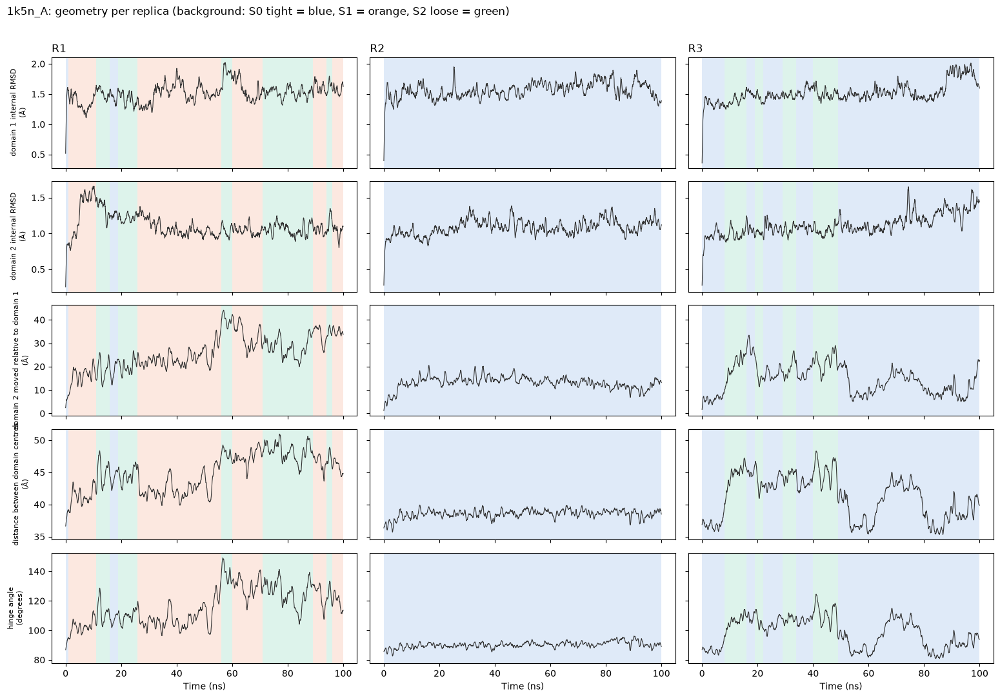

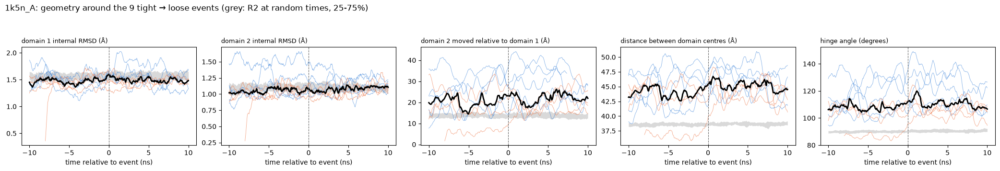

Step = mean(1..3 ns after) - mean(-4..-2 ns before)
signal                                        median step   R2: 95% of |steps| below  events beyond that
domain 1 internal RMSD (Å)                          -0.01                       0.15                 3/9
domain 2 internal RMSD (Å)                          -0.06                       0.17                 0/9
domain 2 moved relative to domain 1 (Å)             -0.10                       2.99                 3/9
distance between domain centres (Å)                  1.43                       0.84                 7/9
hinge angle (degrees)                                3.80                       3.04                 7/9

Mean per joint state (1 ns windows, all replicas):
signal                                              S0        S1        S2
domain 1 internal RMSD (Å)                        1.55      1.51      1.51
domain 2 internal RMSD (Å)                        1.11      1.10      1.09
domain 2 moved relative to domain 1 (Å)  

In [42]:
# ---- Geometric check: do the domains move as rigid blocks around the hinge? ----
# Independent of contacts and betweenness: only atom positions.
#   internal RMSD domain 1 / domain 2 : each domain superposed on itself -> shape change inside the domain
#   domain 2 relative to domain 1     : superpose on domain 1, then RMSD of domain 2 -> how much domain 2 moved
#                                       relative to domain 1 (includes rotation and translation)
#   centre distance / hinge angle     : distance between the domain centres, and the angle
#                                       domain 1 centre - hinge centre - domain 2 centre
# Reference structure: the first frame of R1 (all ATLAS replicas start from the same structure).

GEOM_PRE = (-4.0, -2.0)      # "before" period for the step size at each event (ns)
GEOM_POST = (1.0, 3.0)       # "after" period


def kabsch(X, ref):
    """Superpose every frame of X (frames x atoms x 3) on ref (atoms x 3).
    Returns RMSD per frame, rotation matrices, and the centres of X and ref."""
    cx, cr = X.mean(axis=1, keepdims=True), ref.mean(axis=0)
    Xc, Rc = X - cx, ref - cr
    H = np.einsum("fai,aj->fij", Xc, Rc)
    U, S, Vt = np.linalg.svd(H)
    d = np.sign(np.linalg.det(U @ Vt))
    D = np.tile(np.eye(3), (len(X), 1, 1)); D[:, 2, 2] = d
    rot = U @ D @ Vt                                   # Xc @ rot ~ Rc
    msd = ((Xc ** 2).sum(axis=(1, 2)) + (Rc ** 2).sum() - 2 * (S[:, 0] + S[:, 1] + d * S[:, 2])) / X.shape[1]
    return np.sqrt(np.clip(msd, 0, None)), rot, cx, cr


def geometry(coords, ref):
    r1, rot1, c1x, c1r = kabsch(coords[:, d1_core], ref[d1_core])
    r2, _, _, _ = kabsch(coords[:, d2_core], ref[d2_core])
    # domain 2 after superposing on domain 1
    d2_moved = (coords[:, d2_core] - c1x) @ rot1 + c1r
    rel = np.sqrt(((d2_moved - ref[d2_core]) ** 2).sum(axis=2).mean(axis=1))
    c1, c2 = coords[:, d1_core].mean(axis=1), coords[:, d2_core].mean(axis=1)
    ch = coords[:, hinge_idx].mean(axis=1)
    v1, v2 = c1 - ch, c2 - ch
    cosang = (v1 * v2).sum(axis=1) / (np.linalg.norm(v1, axis=1) * np.linalg.norm(v2, axis=1))
    smooth = lambda x: uniform_filter1d(x.astype(float), sm, mode="nearest")
    return {
        "domain 1 internal RMSD (Å)": smooth(r1),
        "domain 2 internal RMSD (Å)": smooth(r2),
        "domain 2 moved relative to domain 1 (Å)": smooth(rel),
        "distance between domain centres (Å)": smooth(np.linalg.norm(c1 - c2, axis=1)),
        "hinge angle (degrees)": smooth(np.degrees(np.arccos(np.clip(cosang, -1, 1)))),
    }


ref_structure = data[P]["coords"][0]
for r in reps:
    if "geom" not in reps[r]:
        coords = data[P]["coords"] if r == "R1" else load_replica(P, r)["coords"]
        reps[r]["geom"] = geometry(coords, ref_structure)
GEOM = list(reps["R1"]["geom"])

# 1) timelines: one column per replica, joint state as background (loose state = green)
fig, axes = plt.subplots(len(GEOM), len(reps), figsize=(5.2 * len(reps), 2.2 * len(GEOM)), sharex=True, sharey="row")
t_frames = data[P]["time_ns"]
for j, r in enumerate(reps):
    st, tw_r = reps[r]["states"], reps[r]["tw"]
    for i, g in enumerate(GEOM):
        ax = axes[i, j]
        for t, s in zip(tw_r, st):
            ax.axvspan(t - 0.5, t + 0.5, color=STATE_COLOURS[s], alpha=0.15, lw=0)
        ax.plot(t_frames[:len(reps[r]["geom"][g])], reps[r]["geom"][g], color="0.2", lw=0.8)
        if j == 0:
            ax.set_ylabel(g.replace(" (", "\n("), fontsize=8)
        if i == 0:
            ax.set_title(r, loc="left")
for ax in axes[-1]:
    ax.set_xlabel("Time (ns)")
fig.suptitle(f"{P}: geometry per replica (background: S0 tight = blue, S1 = orange, S2 loose = green)",
             x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.97)); plt.show()

# 2) the same signals aligned at the events from the event-alignment cell, with R2 at random times as reference
rng_geo = np.random.default_rng(RANDOM_STATE + 1)
null_t0 = rng_geo.integers(hw, len(reps["R2"]["geom"][GEOM[0]]) - hw, N_NULL) if "R2" in reps else []
fig, axes = plt.subplots(1, len(GEOM), figsize=(4.2 * len(GEOM), 3.6))
for ax, g in zip(axes, GEOM):
    if len(null_t0):
        Nl = np.array([cut(reps["R2"]["geom"][g], t0) for t0 in null_t0])
        ax.fill_between(rel_t, np.nanpercentile(Nl, 25, axis=0), np.nanpercentile(Nl, 75, axis=0),
                        color="0.85", lw=0)
    E = np.array([cut(reps[r]["geom"][g], t0) for r, t0, _ in events])
    for (r, t0, _), e in zip(events, E):
        ax.plot(rel_t, e, color=REP_COLOURS[r], lw=0.6, alpha=0.6)
    ax.plot(rel_t, np.nanmedian(E, axis=0), color="black", lw=2)
    ax.axvline(0, color="0.4", ls="--", lw=0.8)
    ax.set_title(g, loc="left", fontsize=9); ax.set_xlabel("time relative to event (ns)")
fig.suptitle(f"{P}: geometry around the {len(events)} tight → loose events (grey: R2 at random times, 25-75%)",
             x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.92)); plt.show()


# 3) step size at the events vs. normal fluctuation (R2 at random times)
def step(x, t0):
    w = cut(x, t0)
    return np.nanmean(w[(rel_t >= GEOM_POST[0]) & (rel_t <= GEOM_POST[1])]) - \
           np.nanmean(w[(rel_t >= GEOM_PRE[0]) & (rel_t <= GEOM_PRE[1])])


print(f"Step = mean({GEOM_POST[0]:g}..{GEOM_POST[1]:g} ns after) - mean({GEOM_PRE[0]:g}..{GEOM_PRE[1]:g} ns before)")
print(f"{'signal':44}{'median step':>13}{'R2: 95% of |steps| below':>27}{'events beyond that':>20}")
for g in GEOM:
    ev = np.array([step(reps[r]["geom"][g], t0) for r, t0, _ in events])
    nl = np.array([step(reps["R2"]["geom"][g], t0) for t0 in null_t0]) if len(null_t0) else np.array([np.nan])
    thr = np.nanpercentile(np.abs(nl), 95)
    print(f"{g:44}{np.nanmedian(ev):13.2f}{thr:27.2f}{f'{(np.abs(ev) > thr).sum()}/{len(ev)}':>20}")

# 4) average per state over all windows of all replicas
print(f"\nMean per joint state (1 ns windows, all replicas):")
print(f"{'signal':44}" + "".join(f"{'S' + str(s):>10}" for s in range(K_REP)))
for g in GEOM:
    vals = np.concatenate([window_mean(reps[r]["geom"][g], width=TN_WIDTH, step=TN_STEP) for r in reps])
    print(f"{g:44}" + "".join(f"{vals[states_all == s].mean():10.2f}" for s in range(K_REP)))

S0 = 'closed': hinge angle 93°, centre distance 39.3 Å, 11.0 interface contacts, 60% of all time
S1 = 'open, in contact': hinge angle 113°, centre distance 43.9 Å, 7.0 interface contacts, 20% of all time
S2 = 'open, loose': hinge angle 116°, centre distance 46.0 Å, 5.3 interface contacts, 20% of all time


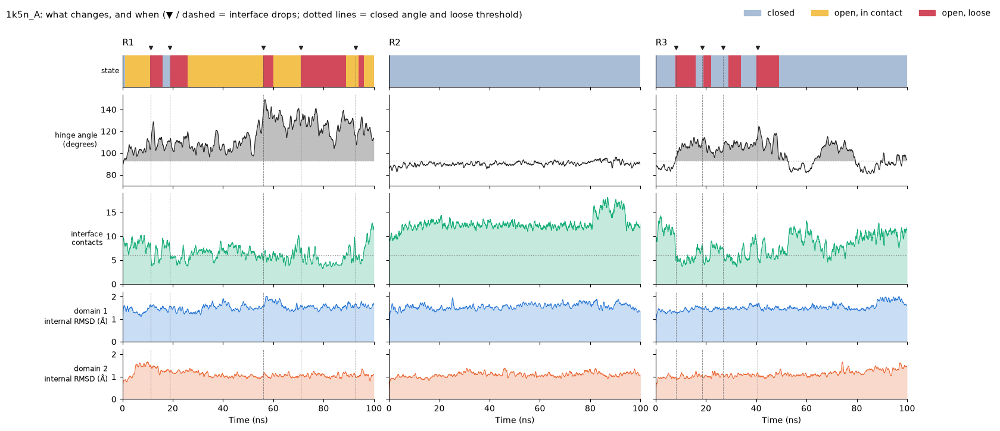

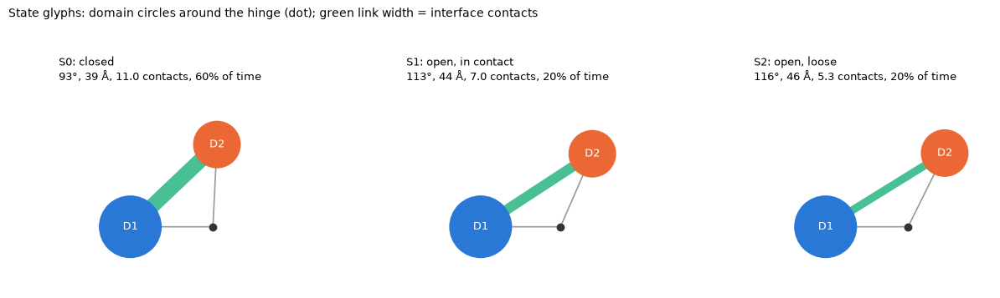

In [43]:
# ---- Prototype: domain swimlanes for 1k5n_A (one column per replica) ----
# Lanes, top to bottom:
#   state            joint state per 1 ns window (closed / open in contact / open and loose)
#   hinge angle      slow lane: opening and closing around the hinge
#   interface        fast lane: contacts between the domains (flickers)
#   domain 1 / 2     rigidity lanes: internal RMSD, shown on a shared scale so "flat" reads as "no change"
# Dashed vertical lines: the tight -> loose events from the event-alignment cell.
from matplotlib.patches import Circle, Rectangle

STATE_NAMES = {0: "closed", 1: "open, in contact", 2: "open, loose"}   # check against the table printed below
STATE_FILL = {0: "#a9bdd6", 1: "#f2c14e", 2: "#d1495b"}
DOM_COLOURS = {"domain 1": "#2a78d6", "domain 2": "#eb6834", "interface": "#1baf7a"}
ANGLE = "hinge angle (degrees)"

# state summary (also used for the glyphs)
summary = {}
for s in range(K_REP):
    ang = np.concatenate([window_mean(reps[r]["geom"][ANGLE], width=TN_WIDTH, step=TN_STEP) for r in reps])
    dist = np.concatenate([window_mean(reps[r]["geom"]["distance between domain centres (Å)"], width=TN_WIDTH, step=TN_STEP) for r in reps])
    summary[s] = dict(angle=ang[states_all == s].mean(), dist=dist[states_all == s].mean(),
                      iface=iface_all[states_all == s].mean(), share=np.mean(states_all == s))
    print(f"S{s} = '{STATE_NAMES[s]}': hinge angle {summary[s]['angle']:.0f}°, centre distance {summary[s]['dist']:.1f} Å, "
          f"{summary[s]['iface']:.1f} interface contacts, {summary[s]['share']:.0%} of all time")

lanes = [("state", 0.35), ("hinge angle\n(degrees)", 1.0), ("interface\ncontacts", 1.0),
         ("domain 1\ninternal RMSD (Å)", 0.55), ("domain 2\ninternal RMSD (Å)", 0.55)]
fig = plt.figure(figsize=(17, 7.5))
gs = fig.add_gridspec(len(lanes), len(reps), height_ratios=[h for _, h in lanes], hspace=0.12, wspace=0.06)
t_frames = data[P]["time_ns"]
ang_max = max(reps[r]["geom"][ANGLE].max() for r in reps)
ifc_max = max(reps[r]["frames"]["iface"].max() for r in reps)
rmsd_max = max(max(reps[r]["geom"]["domain 1 internal RMSD (Å)"].max(), reps[r]["geom"]["domain 2 internal RMSD (Å)"].max()) for r in reps)
closed_angle = summary[0]["angle"]

for j, r in enumerate(reps):
    R = reps[r]
    n = len(R["geom"][ANGLE]); t = t_frames[:n]
    ev_times = [t0 * dt for rr, t0, _ in events if rr == r]
    axes = [fig.add_subplot(gs[i, j]) for i in range(len(lanes))]

    # state lane
    ax = axes[0]
    for tt, s in zip(R["tw"], R["states"]):
        ax.add_patch(Rectangle((tt - 0.5, 0), 1.0, 1, color=STATE_FILL[s], lw=0))
    for te in ev_times:
        ax.plot(te, 1.25, marker="v", color="0.15", ms=5, clip_on=False)
    ax.set_ylim(0, 1); ax.set_yticks([])
    ax.set_title(r, loc="left", fontsize=11, pad=12)

    # slow lane: hinge angle, shaded above the closed level
    ax = axes[1]
    a = R["geom"][ANGLE]
    ax.fill_between(t, closed_angle, a, where=a > closed_angle, color="0.75", lw=0)
    ax.plot(t, a, color="0.15", lw=0.9)
    ax.axhline(closed_angle, color="0.5", ls=":", lw=0.8)
    ax.set_ylim(min(70, closed_angle - 15), ang_max * 1.03)

    # fast lane: interface contacts, loose periods highlighted
    ax = axes[2]
    ic = R["frames"]["iface"]
    ax.fill_between(t, 0, ic, color=DOM_COLOURS["interface"], alpha=0.25, lw=0)
    ax.plot(t, ic, color=DOM_COLOURS["interface"], lw=0.9)
    ax.axhline(LOOSE, color="0.5", ls=":", lw=0.8)
    ax.set_ylim(0, ifc_max * 1.05)

    # rigidity lanes: same y-scale for both domains, so flat = no change
    for ax, name in [(axes[3], "domain 1"), (axes[4], "domain 2")]:
        y = R["geom"][f"{name} internal RMSD (Å)"]
        ax.fill_between(t, 0, y, color=DOM_COLOURS[name], alpha=0.25, lw=0)
        ax.plot(t, y, color=DOM_COLOURS[name], lw=0.8)
        ax.set_ylim(0, rmsd_max * 1.1)

    for i, ax in enumerate(axes):
        for te in ev_times:
            ax.axvline(te, color="0.3", ls="--", lw=0.6, alpha=0.7)
        ax.set_xlim(t[0], t[-1])
        for sp in ["top", "right"]:
            ax.spines[sp].set_visible(False)
        if i < len(lanes) - 1:
            ax.set_xticklabels([])
        if j == 0:
            ax.set_ylabel(lanes[i][0], fontsize=8.5, rotation=0, ha="right", va="center")
        elif i > 0:
            ax.set_yticklabels([])
    axes[-1].set_xlabel("Time (ns)")

handles = [Rectangle((0, 0), 1, 1, color=STATE_FILL[s]) for s in range(K_REP)]
fig.legend(handles, [STATE_NAMES[s] for s in range(K_REP)], loc="upper right", ncol=K_REP, frameon=False,
           bbox_to_anchor=(0.99, 1.0))
fig.suptitle(f"{P}: what changes, and when (▼ / dashed = interface drops; dotted lines = closed angle and loose threshold)",
             x=0.01, ha="left", fontsize=11)
plt.show()


# ---- State glyphs: each state drawn as two blocks around the hinge ----
# circle area ~ domain size, angle and distance = state average, link width = interface contacts
fig, axes = plt.subplots(1, K_REP, figsize=(4.2 * K_REP, 3.6))
n1, n2 = len(d1_core), len(d2_core)
scale = 1.0 / max(summary[s]["dist"] for s in summary)
for ax, s in zip(axes, range(K_REP)):
    S = summary[s]
    theta = np.radians(S["angle"])
    arm = S["dist"] / (2 * np.sin(theta / 2)) * scale          # equal arms reproduce the centre distance
    hinge = np.array([0.0, 0.0])
    c1 = hinge + arm * np.array([-1.0, 0.0])
    c2 = hinge + arm * np.array([-np.cos(theta), np.sin(theta)])
    r1, r2 = 0.22 * np.sqrt(n1 / max(n1, n2)), 0.22 * np.sqrt(n2 / max(n1, n2))
    ax.plot(*np.array([c1, hinge, c2]).T, color="0.6", lw=1.2, zorder=1)
    ax.plot(*np.array([c1, c2]).T, color=DOM_COLOURS["interface"], lw=1 + 12 * S["iface"] / max(summary[q]["iface"] for q in summary), alpha=0.8,
            solid_capstyle="round", zorder=1)
    ax.add_patch(Circle(c1, r1, color=DOM_COLOURS["domain 1"], zorder=2))
    ax.add_patch(Circle(c2, r2, color=DOM_COLOURS["domain 2"], zorder=2))
    ax.plot(*hinge, "o", color="0.2", ms=6, zorder=3)
    ax.text(*c1, "D1", color="white", ha="center", va="center", fontsize=9, zorder=4)
    ax.text(*c2, "D2", color="white", ha="center", va="center", fontsize=9, zorder=4)
    ax.set_title(f"S{s}: {STATE_NAMES[s]}\n{S['angle']:.0f}°, {S['dist']:.0f} Å, {S['iface']:.1f} contacts, "
                 f"{S['share']:.0%} of time", fontsize=9, loc="left")
    ax.set_xlim(-1.1, 0.6); ax.set_ylim(-0.45, 1.0); ax.set_aspect("equal"); ax.axis("off")
fig.suptitle("State glyphs: domain circles around the hinge (dot); green link width = interface contacts",
             x=0.01, ha="left", fontsize=10)
plt.tight_layout(rect=(0, 0, 1, 0.9)); plt.show()